# LASSI - Power Efficiency

**OLLAMA API** + **Argo Gateway API** Jupyter Notebook version

+ ***Post LASSI-Judge version with pass@k***
+ No translation
+ Source code scripts from:
https://github.com/zjin-lcf/HeCBench/tree/master/src

Power measurements: https://pypi.org/project/nvidia-ml-py/  (pynvml)

In [1]:
import pynvml
pynvml.nvmlInit()
print(pynvml.nvmlSystemGetDriverVersion())
pynvml.nvmlShutdown()

560.35.05


In [2]:
!nvidia-smi

Sun Sep  7 13:36:15 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 560.35.05              Driver Version: 560.35.05      CUDA Version: 12.6     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A30                     Off |   00000000:99:00.0 Off |                    0 |
| N/A   34C    P0             30W /  165W |       1MiB /  24576MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [3]:
!nvcc --version 

nvcc: NVIDIA (R) Cuda compiler driver
Copyright (c) 2005-2024 NVIDIA Corporation
Built on Tue_Oct_29_23:50:19_PDT_2024
Cuda compilation tools, release 12.6, V12.6.85
Build cuda_12.6.r12.6/compiler.35059454_0


## Setup

In [4]:
import os
import json
import csv
import time
from datetime import datetime
from zoneinfo import ZoneInfo

# Import LASSI modules
import lassi.llm_config
# import lassi.pipeline # The Pipeline script calls the other LASSI libraries not imported here.
import lassi.pipeline_v3
from lassi.format_colors import color
from lassi.prompt_dictionary import PromptDictionary

# Enable the autoreload extension
%load_ext autoreload
%reload_ext autoreload

# Reload all modules imported with %aimport every time before executing subsequent code.
%autoreload 1

# We need to reload the libraries while under development
%aimport lassi.format_colors
%aimport lassi.prompt_dictionary
%aimport lassi.llm_config
%aimport lassi.llm_methods
%aimport lassi.pipeline_v3
%aimport lassi.get_power
%aimport lassi.argostream_curl
%aimport lassi.code_manager

## Code Generation Experiment - Setup + Run

_____
***STEP 1/2: Input experimental configuration parameters in the following method.***

In [5]:
def experimental_setup():
    # Load config file with source application names and input parameters
    with open("source_apps.json", "r") as f:
        source_apps = json.load(f)
    
    """
    [1] ENTER APPLICATION FOLDER NAME FROM HeCBench
        >> Execution input parameters provided.
    
    HeCBench apps:
    -- matrix-rotate ["30000", "100"]  ["10000", "1"]  # Usage: %s <matrix size> <repeat>
    -- jacobi [""] (none required)
    -- layout ["2500"] ["1"]
    -- atomicCost ["16", "10"] ["1"]
    -- segment-reduce ["16384", "100"] (a replacement for atomicCost, same "Data compression and reduction" category in HeCBench)
    -- dense-embedding ["100000", "128", "100"] ["10000", "8", "1"]
    -- pathfinder ["100000", "10000", "2500"] ["100000", "1000", "5"] ["10000", "1000", "1000"]  # Usage: <column length> <row length> <pyramid_height>
    -- bsearch ["8388608", "1000"] ["10000", "1"]  # Usage: <number of elements> <repeat>
    -- entropy ["8192", "8192", "500"] ["10000", "1024", "1"]  # Usage: <width> <height> <repeat>
    -- colorwheel ["10000", "256", "500000"] ["10000", "8", "1"]  # Usage: <range> <size> <repeat>
    -- randomAccess ["10"] ["1"]  # Usage: <repeat>
    -- lid-driven-cavity [""]

    Altis apps:
    -- level1/bfs ["--size 3"]
    -- level2/raytracing [""]
    -- level2/mandelbrot ["--imageSize 1024 --iterations 100000"]

    Miniapps:
    -- miniMDock ["-lfile", "./input/7cpa/7cpa_ligand.pdbqt", "-nrun 100"]
    
    """

    # ****************************
    # ---> EXPERIMENT UPDATE FIELD
    
    # Enter source application to process through LASSI
    source_collection = "HeCBench"  # "Miniapps" "HeCBench"
    source_app = "randomAccess"  # "miniMDock" jacobi
    make_script = False  # Used only for Miniapps
    
    build_script = False  # False (for HeCBench) Use for Altis only
    

    """
    Valid source code folder names (under source_codes):
    1. HeCBench
    2. altis/src/cuda
    3. miniMDock/bin/
    """
    source_folder = source_apps[source_collection]["source_folder"]  # "altis/src/cuda/level2"    #  "HeCBench" "altis/src/cuda/level1"
    app_folder_name = source_apps[source_collection][source_app]["app_folder"]
    lines_of_code = source_apps[source_collection][source_app]["code_lines"]
    if make_script:
        app_name = app_folder_name
        file_name = "kernels"
    else:
        app_name = "mt_" + app_folder_name + "-cuda_main"
        file_name = ""

    
    """
    [2] SELECT THE CODE TRANSLATION MAPPING DIRECTION EXPERIMENT CONFIGURATION
    
    CUDA -- OMP -- HIP -- SYCL -- FORTRAN
    """   
    # These should be the same if *not* doing translation.
    source_lang = "CUDA"
    target_lang = "CUDA"

    test_code_first = True  # True or False
    verifyprompt = False  # True or False -- Print out LLM prompt in stdout to preview
    
    # TOGGLE USE CODE KNOWLEDGE CONTEXT FOR TARGET
    use_context_summaries_only = True  # True or False
    few_shot_learning = False  # True or False
    run_code_analysis = False  # True or False
    
    # THESE WILL NO LONGER BE OPTIONS
    use_context = False  # True or False -- NOT USED IN v2, v3
    use_self_prompting = False  # True or False -- NOT USED IN v2, v3
    baseline_oneshot_goal = True  # True or False -- NOT USED IN v2, v3
    

    # TOGGLE USE OF POWER MEASUREMENT DURING EXE
    power_measure = True  # True or False
    vary_llm_temp = True  # True or False

    # TOGGLE ENERGY EFFICIENCY SELF-CORRECTION FEEDBACK
    yes_power_feedback = True  # True or False

    # ASSIGN CODE COMPILE COMMAND
    code_build_script = ""
    code_compiler = ""
    code_compiler_kwds = ""
    if source_lang == "CUDA":
        if build_script:
            code_build_script = "build_" + app_name
        elif make_script:
            code_compiler = "make"
            code_compiler_kwds = "API=CUDA DEVICE=GPU CARD=NVIDIA NUMWI=64"
        else:
            code_compiler = "nvcc"
            code_compiler_kwds = "-std=c++14 -Xcompiler -Wall -arch=sm_80 -O3"
            # -arch=sm_70 for aiops01 GPU (Argonne)  # -arch=sm_80 for A100s
            # -arch=sm_60 for P100
            # -arch=sm_89 for RTX 5000
        if yes_power_feedback:
            context_knowledge_selection = "cuda_optimization_summary"
            context_fewshot_examples = "cuda_c_few_shot_examples"
        else:
            context_knowledge_selection = "cuda"
    elif source_lang == "OMP":
        # For A100 on Linux_x86_64 or Linux_aarch64
        code_compiler = "g++" # "/opt/nvidia/hpc_sdk/Linux_aarch64/2024/compilers/bin/nvc++"  # 
        code_compiler_kwds = "-fopenmp -O3" # "-Wall -O3 -Minfo -mp=gpu -gpu=cc80"  # -c
        # !! TODO - REVIEW: code_compiler_kwds = "-Wall -O3 -Minfo=accel -mp=gpu -gpu=cc80"  # "-fopenmp -O3 -c"
        # For RTX 5000 Ada on Linux x86_64:
        # code_compiler = "/opt/nvidia/hpc_sdk/Linux_x86_64/25.7/compilers/bin/nvc++" # "g++"
        # code_compiler_kwds = "-Wall -O3 -Minfo=accel -mp=gpu -gpu=cc89"  # "-fopenmp -O3"
        context_knowledge_selection = "omp"

    # TOGGLE EXECUTE PIPELINE
    yes_execute = True  # True / False
    if yes_execute:
        # Enter execution input parameters, if needed
        # A list of parameter string values, e.g., ["10000", "1
        # ****************************
        # ---> EXPERIMENT UPDATE FIELD - Now, automated:
        exe_input_parameters = source_apps[source_collection][source_app]["app_params"]
    else:
        exe_input_parameters = [""]

    
    """
    [3] SELECT THE LLM TO USE FOR THE CODE TRANSLATION EXPERIMENT
    """
    # SELECT A MODEL

    # ****************************
    # ---> EXPERIMENT UPDATE FIELD
    
    # -- FROM ARGO:
    # model = "gpt35"  # (max token = 4096)
    # model = "gpt35large"  # (max token = 16384)
    # model = "gpt4large"  # (max token = 32768)
    # model = "gpt4turbo"  # (max token = 128000)
    model = "gpto4mini"  # (max token = 128000)
    model_coder = "gpto4mini"  # (max token = 128000)
    # model = "gpt4olatest"  # (max token = 128000)
    # model_coder = "gpt4olatest"  # (max token = 128000)
    # model_coder = "gpt4o"  # (max token = 128000)
    # model_coder = "gpt4olatest"  # (max token = 128000)
    # model = "gpt4olatest"  # (max token = 200000)
    # model_coder = "gpt4olatest"  # (max token = 200000)
    model_judge = "gpt41"  # (max token = 200000)

    # -- FROM CEREBRAS
    # model = "gpt-oss-120b"
    # model_judge = "gpt-oss-120b"
    # model_coder = "qwen-3-coder-480b"
    
    # -- FROM OLLAMA
    # model = "devstral:24b" # (max token = 128000)
    # model_coder = "devstral:24b" # (max token = 128000)
    # model_judge = "devstral:24b" # (max token = 128000)
    # model = "qwq:latest"  # (max token = 128000)
    # model_coder = "qwen2.5-coder:32b"  # (max token = 32768)
    # model_judge = "qwq:latest"  # (max token = 128000)
    # model = "qwq:latest"  # (max token = 131072)
    # model = "gemma3:27b"  # crashing on code gen
    # model_coder = "gemma3:27b"
    # model = "granite3.2:8b-instruct-q8_0"
    # model_coder = "granite-code:34b-instruct-q8_0"
    # model = "deepseek-r1:70b"  # (max token = 128000)
    # model_coder = "deepseek-r1:70b"  # (max token = 128000)
    # model_coder = "deepseek-coder-v2:16b"  # (max token = 131072)
    # model_coder = "deepseek-coder-v2:16b"  # (max token = 131072)
    # model = "dolphin3"  # (max token = 131072)
    # model = "llama3.3:latest"  # (max token = 131072)
    # model = "phi4" # (max token = 16384)
    # model_coder = "codestral:22b"  # (max token = 32768)
    # model = "codestral:22b-v0.1-q8_0"  # (max token = 32768)
    # model = "wizardcoder:33b-v1.1-q8_0"  # (max token = 16384)
    # model_coder = "deepseek-coder:33b-instruct-q8_0"  # (max token = 16384)
    # model = "deepseek-coder-v2:16b-lite-instruct-fp16"  # (max token = 128000)
    # model = "deepseek-coder-v2:16b-lite-instruct-q8_0"
    # model = "phi3:14b"  # (max token = 131072)
    # model_judge = "llama3.3:70b"  # (max token = 128000)
    # model = "qwen3:latest"
    # model_coder = "qwen3:latest"
    # model_judge = "qwen3:latest"  # (max token = 40960)
    # model_coder = "qwen3-coder:30b"  # context 262144
    # model = "gpt-oss:20b"
    # model_judge = "gpt-oss:20b"
  
    # Set maximum context token count size for selected LLM:
    num_ctx = 200000
    num_ctx_coder = 200000

    # Needed only for Argo endpoints
    uri = "local"  # local  remote

    # ASSIGN LLM API SOURCE:
    if model in ["gpt35", "gpt35large", "gpt4", "gpt4large", "gpt4turbo", "gpt4o", "gpt4olatest",
                 "gpto1preview", "gpto1mini", "gpto3mini", "gpto4mini", "claudesonnet4"]:
        llm_source = "argo"
    elif model in ["gpt-oss-120b", "qwen-3-coder-480b"]:
        llm_source = "cerebras"
    elif ("GGUF" in model and "hf.co" not in model):
        llm_source = "lmstudio"
    else:
        llm_source = "ollama"

    """
    [4] SET ADDITIONAL PIPELINE PARAMETERS
    """
    experiment = "exp0925_" + model + "_" + app_folder_name + "_ee"  # Assign any label for experiment name.
    display_response = True
    test_with_error = False
    generate_test_case = False

    # Unload any previously loaded LLMs in the Ollama server 
    # (clear out the memory)
    if llm_source == "ollama":
        lassi.llm_config.unload_ollama_model(model)
        lassi.llm_config.unload_ollama_model(model_coder)

    """
    [5] SET DATA COLLECTION CONFIGURATION
    """
    # Data spreadsheet column headers
    DATAFIELDNAMES = [
        "trial_number",
        "timestamp",
        "experiment",
        "app_name",
        "code_line_count",
        "llm",
        "llm_coder",
        "llm_judge",
        "source_v0_energy_J",
        "source_v0_avg_power_W",
        "source_v0_runtime_s",
        "base_v1_energy_J",
        "base_v1_avg_power_W",
        "base_v1_runtime_s",
        "base_v1_valid",
        "base_v1_energy_diff",
        "base_v1_avg_power_diff",
        "base_v1_runtime_diff",
        # "base_v1_optimization_methods",
        # "base_v2_energy_J",
        # "base_v2_avg_power_W",
        # "base_v2_runtime_s",
        # "base_v2_valid",
        # "base_v2_selfcorrections",
        # "base_v2_energy_diff",
        # "base_v2_avg_power_diff",
        # "base_v2_runtime_diff",
        # "base_v2_optimization_methods",
        "lassiee_energy_J",
        "lassiee_avg_power_W",
        "lassiee_runtime_s",
        "lassiee_valid",
        "lassiee_version",
        "lassiee_llm_temp",
        "lassiee_selfcorrections",
        "lassiee_eeiterations",
        "lassiee_energy_diff",
        "lassiee_avg_power_diff",
        "lassiee_runtime_diff",
        "lassiee_optimization_methods",
        "total_selfcorrections",
        "total_eeiterations",
        "pipeline_runtime_min"
    ]
    
    return (app_folder_name, app_name, file_name, lines_of_code, source_lang, target_lang, model, model_coder, model_judge, num_ctx, num_ctx_coder, llm_source, use_context, use_context_summaries_only,
            few_shot_learning, run_code_analysis, context_knowledge_selection, source_folder, code_compiler, code_compiler_kwds, build_script, make_script, code_build_script, yes_execute, exe_input_parameters,
            experiment, display_response, test_with_error, generate_test_case, power_measure, test_code_first, yes_power_feedback, baseline_oneshot_goal, use_self_prompting, vary_llm_temp,
            verifyprompt, DATAFIELDNAMES)

# EXPERIMENTAL DATA COLLETION MANAGEMENT
def init_data_collection(dir_path, DATAFIELDNAMES, filename="lassi-ee_pipeline_data.csv"):
    os.makedirs(dir_path, exist_ok=True)
    fp = os.path.join(dir_path, filename)
    if not os.path.exists(fp):
        with open(fp, "w", newline="") as f:
            writer = csv.DictWriter(f, fieldnames=DATAFIELDNAMES)
            writer.writeheader()
    return fp

_____
***STEP 2/2: Run the following block to implement the pipeline with the configuration parameters.***


***** EXPERIMENT CONFIGURATION SUMMARY *****

Date-time: 09-07-2025_t08_36_16
Application: randomAccess

EE Refactoring: CUDA_ee

LLM Source: argo
Model: gpto4mini
Model coder: gpto4mini
Model judge: gpt41
System Prompt Index: CUDA
Code file template: generated_codes/argo_gpto4mini/promptset_CUDA/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee

LLM System Prompt: 

You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code for energy efficiency by reducing GPU and CPU power consumption without losing any functionality of the original code. You must also carefully read and incorporate the best practices from the provided background documents. You always surround your generated code with the three characters ```.

Power measurement: True



***** BEGIN THE LASSI ENERGY EFFICIENCY PIPELINE (v3) ***** Trial #: 1



----- GPU Memory Status:
 GPU 0: 408 MiB used, 24167 MiB free, 24576 MiB total

----- GPU State:
clocks.current.graph

Waiting for the system to settle down for 1 seconds...: 100%|████████████████████████████████████████████| 1/1 [00:01<00:00,  1.00s/it]


executable_file:  /home/cc/lassi/LASSI-EE/source_codes/HeCBench/randomAccess/randomAccess-cuda_main
initial_dir:  /home/cc/lassi/LASSI-EE
directory_path:  /home/cc/lassi/LASSI-EE/source_codes/HeCBench/randomAccess
executable:  randomAccess-cuda_main
Working directory: /home/cc/lassi/LASSI-EE/source_codes/HeCBench/randomAccess
Execute command: ['./randomAccess-cuda_main', '10']

running: executable -  randomAccess-cuda_main

----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION > -----

Table size = 67108864
Main table size   = 2^26 = 67108864 words
Number of updates = 536870912
Average kernel execution time: 0.844148 (s)
Found 0 errors in 67108864 locations (PASS).

----- < END: Standard Output > -----

GPU power data has been written to source_CUDA_gpu_net_power_results.csv


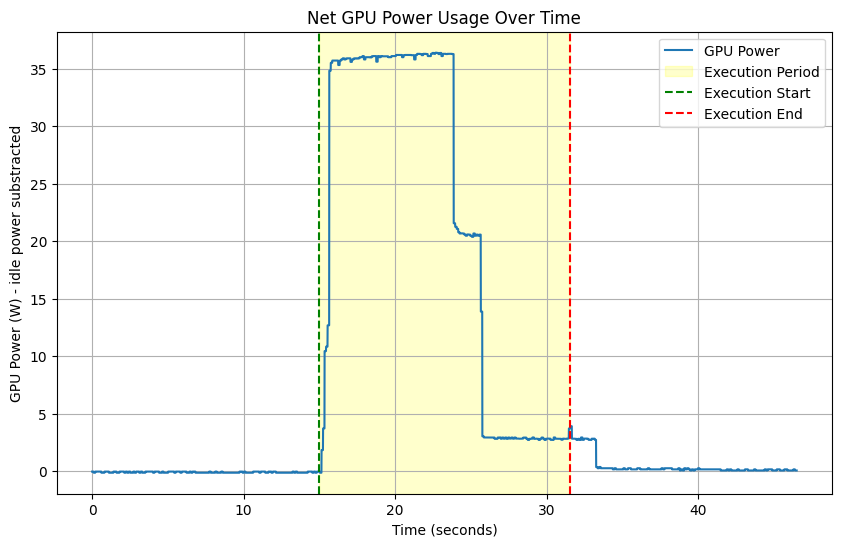

Start time: 15.0 -- End time: 31.502
Net (idle corrected) GPU energy consumption for source_CUDA_gpu_net_power_results.csv:
  0.000099 kWh
  0.0985 Wh
  354.70 J
Average GPU power: 21.50 W +/- 15.40 
 with sample standard deviation.
Net Energy During Exe Runtime:   354.70 J
Code execution duration:  16.50 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

----- >>> System check AFTER exe code...

----- GPU Memory Status:
 GPU 0: 408 MiB used, 24167 MiB free, 24576 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 30.62 W, P0



Measure system idle power...
Duration for idle time measurement: 16.5
GPU power data has been written to idle__gpu_net_power_results.csv


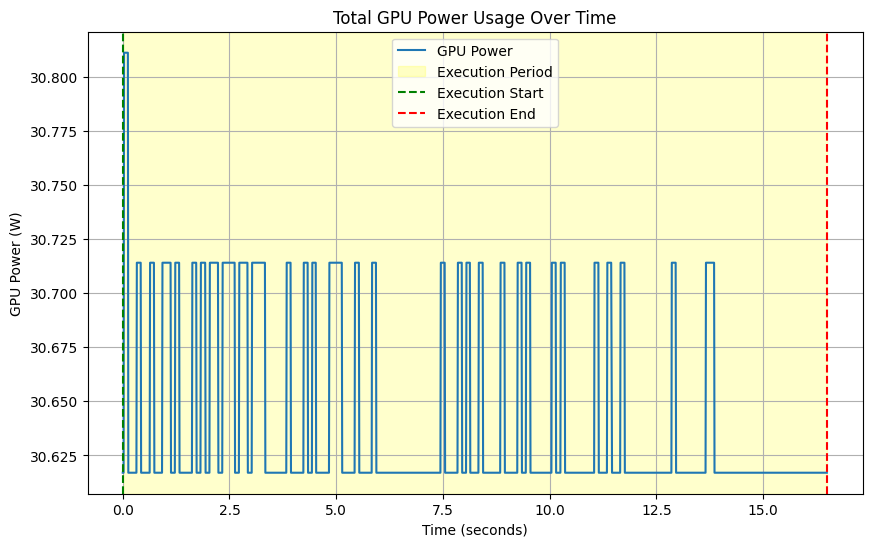

Start time: 0 -- End time: 16.502
Total GPU energy consumption for idle__gpu_net_power_results.csv:
  0.000140 kWh
  0.1404 Wh
  505.59 J
Average GPU power: 30.64 W +/- 0.04 
 with sample standard deviation.
Total Energy During Exe Runtime:   505.59 J
Code execution duration:  16.50 seconds
----------------------------------------------------------------------------------------------------------------------------------------

----- END OF STAGE 0: TEST SOURCE -----

None

*** DEBUG: code_version: 0 | tracking_best_version: 0 ***


--> ... prompt LLM to perform code analysis.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code analysis -----



=====
{
  "assumptions": [
    "TableSize is a power of two, so bit‐masking (TableSize-1) implements modulo indexing.",
    "NUPDATE is divisible by 128 (K2_BLOCKSIZE), so each of the 128 threads in the update kernel does an equal number of updates.",
    "The 64‐bit linear‐feedback shift register (LFSR) RNG has sufficient period and state fits in a u64Int.",
    "Single‐block execution for the update kernel (<<<1,128>>>) suffices to cover all threads since 128 threads × updates/thread = NUPDATE.",
    "AtomicXor on 64‐bit words is supported and provides correct concurrent updates to Table entries."
  ],
  "invariants": [
    "TableSize remains constant throughout host and device code.",
    "NUPDATE is a compile‐time constant and does not change at runtime.",
    "After initTable, Table[i] == i for all 0 <= i < TableSize.",
    "ran[j] initially holds HPCC_starts((NUPDATE/128) * j) and then follows the LFSR recurrence exactly.",
    "The mapping ran[j] & (TableSize-1) always stays within table bounds due to power‐of‐two sizing."
  ],
  "design_patterns": [
    "Data‐parallel initialization and update kernels: initTable and update operate per‐thread over data indices.",
    "Separation of concerns: RNG logic (HPCC_starts) is isolated in a __device__ function, kernels handle memory ops.",
    "Thread‐per‐data‐chunk pattern: each of 128 threads processes NUPDATE/128 updates.",
    "Atomic operations pattern: atomicXor ensures correctness under concurrent random writes.",
    "Loop unrolling (#pragma unroll) for small fixed‐count loops in HPCC_starts to reduce branch overhead."
  ],
  "memory_access_patterns": [
    "initTable: coalesced, contiguous writes (Table[i]=i) across threads in a 1D grid.",
    "update: random, uncoalesced atomic writes to Table at indices based on the LFSR output (ran[j] & (TableSize-1)).",
    "update: each thread writes its private ran[j] slot and reads it in subsequent iterations—likely cached in registers or per‐thread local memory.",
    "Host‐to‐device copy of Table only once before the loop and device‐to‐host copy only once after all repeats; kernels reuse the same device buffer."
  ],
  "memory_allocation_deallocation": [
    "Host: posix_memalign(&Table, 1024, TableSize*sizeof(u64Int)); free(Table) at end.",
    "Device: cudaMalloc(&d_Table, TableSize*sizeof(u64Int)); cudaFree(d_Table) at end.",
    "Device: cudaMalloc(&d_ran, 128*sizeof(u64Int)); cudaFree(d_ran) at end.",
    "Data transfer: cudaMemcpy(d_Table) omitted, as initTable kernel reinitializes; cudaMemcpy back host happens after kernel loop."
  ],
  "other_key_characteristics": [
    "Runtime repeat loop on the host to amortize variability: timing covers multiple kernel launches.",
    "High‐resolution timing with std::chrono to report average kernel execution time excluding allocation overhead.",
    "Host‐side validation uses the same LFSR logic to recompute the expected Table and count errors.",
    "Use of long long and unsigned long long for cross‐platform 64‐bit consistency.",
    "Single‐block update kernel limits occupancy but simplifies inter‐thread coordination via atomicXor."
  ]
}
=====



----- STARTING STAGE 1: BASE LLM REFACTORING WITHOUT SELF-CORRECTION  -----


*** DEBUG: code_version: 1 | tracking_best_version: 0 ***

----- REVIEW THE ZERO-SHOT INSTRUCTIONS TASK PROMPT  (prompt token count, excluding code): 1397


--> ... initial zero-shot attempt: prompt the LLM to generate code.



----- STARTING CODE GENERATION -----


=====< LLM Prompt Not Shown >=====





----- THE GENERATED CODE -----

(hidden)




----- POST-PROCESSING of GENERATED CODE -----


*** DEBUG: code_version: 1 | tracking_best_version: 0 ***
saving to file_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial1.cu
Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial1.cu', '-o', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial1']

Compilation of code successful!


Execute file: /home/cc/lassi/LASSI-EE/g

Waiting for the system to settle down for 5 seconds...: 100%|████████████████████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


executable_file:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial1
initial_dir:  /home/cc/lassi/LASSI-EE
directory_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16
executable:  randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial1
Working directory: /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16
Execute command: ['./randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial1', '10']

running: executable -  randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial1

----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION > -----

Table size = 2^26 = 6710

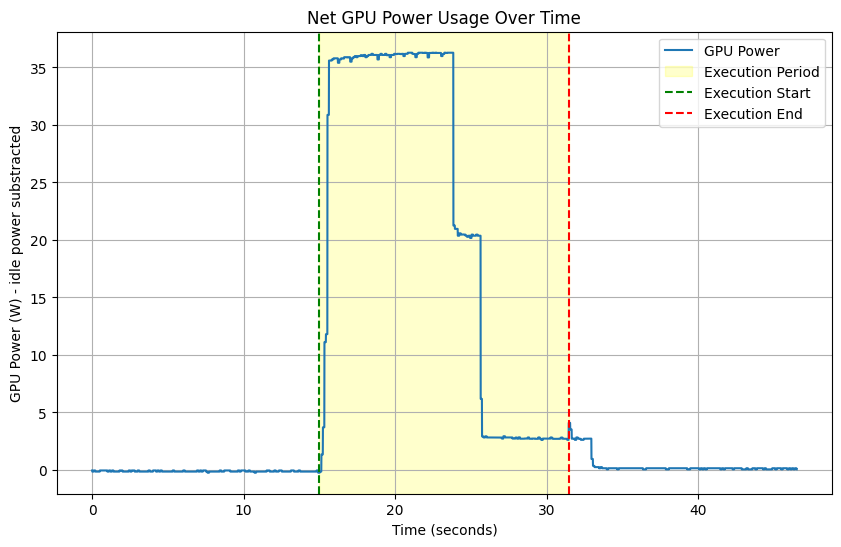

Start time: 15.0 -- End time: 31.493
Net (idle corrected) GPU energy consumption for generated_CUDA_gpu_net_power_results.csv:
  0.000099 kWh
  0.0988 Wh
  355.68 J
Average GPU power: 21.57 W +/- 15.46 
 with sample standard deviation.
Net Energy During Exe Runtime:   355.68 J
Code execution duration:  16.49 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

----- >>> System check AFTER exe code...

----- GPU Memory Status:
 GPU 0: 408 MiB used, 24167 MiB free, 24576 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 30.81 W, P0

--> SAVING code version: 1


----- POWER METRICS Feedback Loop  -----


*** DEBUG: code_version: 1 | tracking_best_version: 0 ***


--> ... prompt LLM to judge the validity of the refactored code.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code validation judge -----



Let's carefully compare the SOURCE CODE and the REFACTORED CODE for functional equivalence and standard output similarity.

---

## 1. **Functional Equivalence**

### **Core Algorithm**

- **Random Number Generator (`HPCC_starts`)**:  
  Both codes implement the same logic for the random number generator, including the double shift and XOR with `POLY`. The REFACTORED CODE uses `__forceinline__`, which is a performance optimization but does not change the logic.

- **Table Initialization (`initTable`)**:  
  Both codes initialize the table such that `Table[i] = i`. The REFACTORED CODE uses `u64Int idx` instead of `int i`, but this is only a type change for correctness with large tables.

- **Table Update Kernel**:  
  - **SOURCE CODE**:  
    Each of 128 threads (`K2_BLOCKSIZE`) computes its own random sequence, stores it in a per-thread array `ran[j]`, and performs `NUPDATE/128` updates per thread.  
  - **REFACTORED CODE**:  
    Each thread computes its own random sequence in a register variable (`ran`), does `nupdatesPerThread` updates, and directly performs atomic XORs. The per-thread array `d_ran` is removed, which is an energy efficiency optimization (less global memory traffic), but the update logic is identical.

- **Validation**:  
  Both codes perform the same validation:  
  - They iterate through all updates, apply the same random sequence and XOR to the table, and count errors (locations where `Table[i] != i`).
  - The error threshold and PASS/FAIL logic are identical.

### **Memory Allocation**

- Both codes allocate the main table with `posix_memalign` and the device table with `cudaMalloc`.
- The REFACTORED CODE omits the device-side `d_ran` array, which is not needed for correctness.

### **Parameter Calculation**

- Both codes compute `TableSize` as the largest power of two that fits in half of 512MB, resulting in `2^26 = 67108864`.
- Both codes use `NUPDATE = 8 * TableSize = 536870912`.

### **Looping and Kernel Launch**

- Both codes launch the same number of threads for initialization and update.
- The REFACTORED CODE computes `nupdatesPerThread` as `totalUpdates / K2_BLOCKSIZE`, which matches the logic in the SOURCE CODE.

---

## 2. **Standard Output Comparison**

### **SOURCE CODE Output**
```
Table size = 67108864
Main table size   = 2^26 = 67108864 words
Number of updates = 536870912
Average kernel execution time: 0.844148 (s)
Found 0 errors in 67108864 locations (PASS).
```

### **REFACTORED CODE Output**
```
Table size = 2^26 = 67108864 words
Main table size   = 2^26 = 67108864 words
Number of updates = 536870912
Average kernel execution time: 0.842600 (s)
Found 0 errors in 67108864 locations (PASS).
```

#### **Differences**
- The REFACTORED CODE prints `Table size = 2^26 = 67108864 words` instead of `Table size = 67108864`. This is a formatting improvement, not a loss of information.
- All other lines are identical in content and layout.
- Minor difference in kernel execution time (0.844148 vs 0.842600) is expected and acceptable.

---

## 3. **Metrics Comparison**

- **Energy, Power, Duration**:  
  Both codes have nearly identical metrics, with the REFACTORED CODE showing a negligible difference in energy and execution time. This is consistent with an energy-efficient refactor.

---

## 4. **Conclusion**

- **Functionality**:  
  The REFACTORED CODE preserves all intended functionality of the SOURCE CODE. All algorithmic steps, memory allocations, kernel launches, and validation are equivalent.
- **Standard Output**:  
  The REFACTORED CODE produces nearly identical output. The only difference is a more informative format for the table size, which is acceptable and does not omit any key information.

---

**Reasoning Summary:**  
The REFACTORED CODE is functionally equivalent to the SOURCE CODE and produces nearly identical standard output, with only minor formatting improvements and negligible differences in timing. All key details are present, and the output is consistent with the original code's intent.

---

**Conclusion:**  
VALID



----- END LLM RESPONSE -----



LLM JUDGE: START CODE ANALYSIS ---- 


--> ... prompt LLM to perform code analysis.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code analysis -----



<result>
pass
</result>

| Criterion Category                | Criteria                                                                                                   | Pass/Fail |
|-----------------------------------|------------------------------------------------------------------------------------------------------------|-----------|
| assumptions                       | TableSize power-of-two, bit-masking for modulo                                                             | pass      |
|                                   | NUPDATE divisible by 128 (K2_BLOCKSIZE)                                                                    | pass      |
|                                   | 64-bit LFSR RNG fits in u64Int                                                                             | pass      |
|                                   | Single-block execution for update kernel (<<<1,128>>>)                                                     | pass      |
|                                   | AtomicXor on 64-bit words supported                                                                        | pass      |
| invariants                        | TableSize constant throughout                                                                              | pass      |
|                                   | NUPDATE is compile-time constant                                                                           | pass      |
|                                   | After initTable, Table[i] == i                                                                             | pass      |
|                                   | ran[j] initialized with HPCC_starts and follows LFSR recurrence                                            | pass      |
|                                   | ran[j] & (TableSize-1) stays in bounds                                                                     | pass      |
| design_patterns                   | Data-parallel init/update kernels                                                                          | pass      |
|                                   | Separation of concerns: RNG logic in __device__ function                                                   | pass      |
|                                   | Thread-per-data-chunk pattern                                                                              | pass      |
|                                   | Atomic operations pattern                                                                                  | pass      |
|                                   | Loop unrolling (#pragma unroll) in HPCC_starts                                                            | pass      |
| memory_access_patterns            | initTable: coalesced writes                                                                                | pass      |
|                                   | update: random, uncoalesced atomic writes                                                                  | pass      |
|                                   | update: per-thread ran[j] in registers/local                                                               | pass      |
|                                   | Host-to-device copy only once before loop, device-to-host only once after                                  | pass      |
| memory_allocation_deallocation    | Host: posix_memalign/free                                                                                  | pass      |
|                                   | Device: cudaMalloc/cudaFree for Table                                                                      | pass      |
|                                   | Device: d_ran allocation omitted as per rubric                                                             | pass      |
|                                   | Data transfer: cudaMemcpy back after kernel loop                                                           | pass      |
| other_key_characteristics         | Runtime repeat loop for timing                                                                             | pass      |
|                                   | High-resolution timing with std::chrono                                                                    | pass      |
|                                   | Host-side validation with same LFSR logic                                                                  | pass      |
|                                   | Use of long long/unsigned long long for 64-bit consistency                                                 | pass      |
|                                   | Single-block update kernel for simplicity                                                                  | pass      |

... (12 outputs left out)



----- THE REFACTORING PLAN PROMPT  (prompt with code, token count: 2874): 



----- REFACTORING PLAN WITH INSTRUCTIONS PROMPT (energy efficiency *iteration* with code, token count: 2992): 

--> ... prompt LLM to generate code for energy efficiency -- improvement iteration.



----- STARTING CODE GENERATION -----


=====< LLM Prompt Not Shown >=====





----- THE GENERATED CODE -----

(hidden)




----- POST-PROCESSING of GENERATED CODE -----


*** DEBUG: code_version: 1 | tracking_best_version: 0 ***
saving to file_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial1.cu
Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial1.cu', '-o', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial1']

Compilation of code successful!


Execute file: /home/cc/lassi/LASSI-EE/g

Waiting for the system to settle down for 5 seconds...: 100%|████████████████████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


executable_file:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial1
initial_dir:  /home/cc/lassi/LASSI-EE
directory_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16
executable:  randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial1
Working directory: /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16
Execute command: ['./randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial1', '10']

running: executable -  randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial1

----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION > -----

Table size = 67108864
Ma

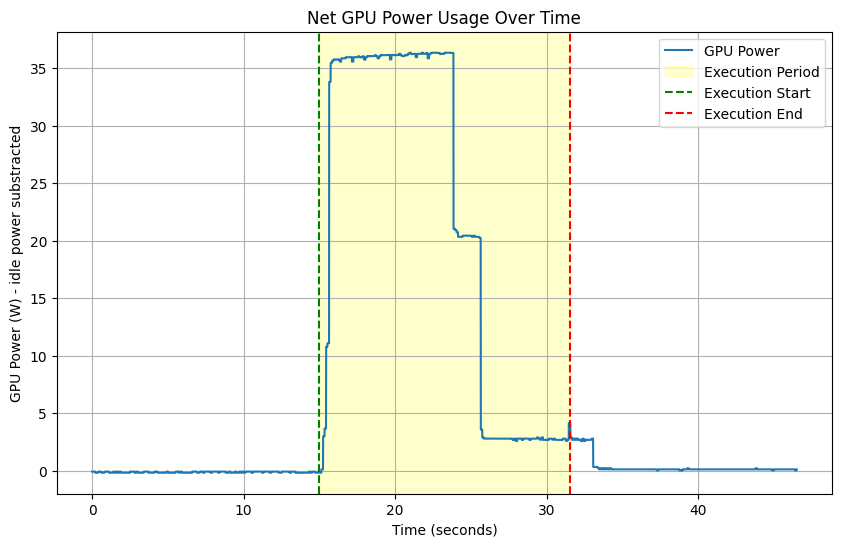

Start time: 15.0 -- End time: 31.515
Net (idle corrected) GPU energy consumption for generated_CUDA_gpu_net_power_results.csv:
  0.000098 kWh
  0.0978 Wh
  351.94 J
Average GPU power: 21.32 W +/- 15.56 
 with sample standard deviation.
Net Energy During Exe Runtime:   351.94 J
Code execution duration:  16.51 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

----- >>> System check AFTER exe code...

----- GPU Memory Status:
 GPU 0: 408 MiB used, 24167 MiB free, 24576 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 30.71 W, P0

--> SAVING code version: 2


----- POWER METRICS Feedback Loop  -----


*** DEBUG: code_version: 2 | tracking_best_version: 0 ***


--> ... prompt LLM to judge the validity of the refactored code.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code validation judge -----



Let's carefully compare the SOURCE CODE and the REFACTORED CODE for functional equivalence and standard output similarity.

---

## 1. **Functional Equivalence**

### **Key Operations in Both Codes**

- **Table Initialization:**  
  Both codes allocate a table of size TableSize and initialize it with indices.

- **Random Number Generation:**  
  Both use the same HPCC_starts device function for random number generation.

- **Update Kernel:**  
  - **SOURCE CODE:**  
    The `update` kernel takes `Table`, `ran`, and `TableSize` as arguments.  
    Each thread initializes `ran[j]` and then performs updates, storing the RNG state in global memory (`d_ran`).
  - **REFACTORED CODE:**  
    The `update` kernel only takes `Table` and `TableSize`.  
    The RNG state is kept in a register-local variable (`ran`), eliminating the need for the `d_ran` array.

- **Validation:**  
  Both codes perform the same validation:  
  - They iterate over all updates, apply the same XOR operation, and count errors.

- **Memory Management:**  
  Both codes allocate and free host and device memory appropriately.

### **Differences**

- **Removal of `d_ran`:**  
  The refactored code eliminates the `d_ran` array and its associated cudaMalloc/cudaFree.  
  This is a safe optimization, as the RNG state is only used locally within each thread and does not need to be stored in global memory.

- **Kernel Arguments:**  
  The update kernel in the refactored code has one fewer argument, but this does not affect functionality.

- **Loop Variables:**  
  The loop variable in the main repeat loop is renamed from `i` to `iter`, which is purely cosmetic.

- **Failure Assignment:**  
  The refactored code uses a ternary operator for `failure`, which is equivalent to the original.

### **Conclusion on Functionality**

- The refactored code preserves all intended functionality:
  - Table initialization, update logic, and validation are unchanged.
  - The removal of `d_ran` does not affect correctness, as its use was redundant.
  - All CUDA kernel launches and host/device memory operations are equivalent.

---

## 2. **Standard Output Comparison**

### **SOURCE CODE Output**
```
Table size = 67108864
Main table size   = 2^26 = 67108864 words
Number of updates = 536870912
Average kernel execution time: 0.844148 (s)
Found 0 errors in 67108864 locations (PASS).
```

### **REFACTORED CODE Output**
```
Table size = 67108864
Main table size   = 2^26 = 67108864 words
Number of updates = 536870912
Average kernel execution time: 0.843667 (s)
Found 0 errors in 67108864 locations (PASS).
```

### **Analysis**

- **Layout:**  
  Both outputs have identical formatting and order of information.

- **Content:**  
  - Table size, main table size, and number of updates are identical.
  - Average kernel execution time differs by a negligible amount (0.844148 vs 0.843667), which is expected due to minor runtime variations and possible efficiency improvements.
  - Validation output ("Found 0 errors ... (PASS).") is identical.

- **Acceptable Differences:**  
  The minor difference in kernel execution time is reasonable and consistent with the refactored code's intended energy efficiency.

---

## 3. **Metrics Comparison**

- **Energy and Power:**  
  The refactored code shows slightly lower energy consumption and average GPU power, which is consistent with the goal of improving energy efficiency.

- **Execution Duration:**  
  Execution duration is nearly identical (16.50 vs 16.51 seconds).

---

## **Final Reasoning and Conclusion**

- **Functionality:**  
  The refactored code preserves all intended functionality of the source code.  
  The removal of the `d_ran` array is a safe optimization and does not affect correctness.

- **Standard Output:**  
  The printed output is nearly identical in layout and content, with only minor, acceptable numerical differences.

- **Metrics:**  
  The metrics are consistent with the goal of energy efficiency.

---

**Conclusion:**  
The REFACTORED CODE is **VALID**.



----- END LLM RESPONSE -----



LLM JUDGE: START CODE ANALYSIS ---- 


--> ... prompt LLM to perform code analysis.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code analysis -----



<result>
fail
</result>

| Criterion Category              | Criteria                                                                 | Pass/Fail |
|---------------------------------|--------------------------------------------------------------------------|-----------|
| assumptions                     | TableSize power-of-two, bit-masking for modulo                           | pass      |
|                                 | NUPDATE divisible by 128 (K2_BLOCKSIZE)                                  | fail      |
|                                 | 64-bit LFSR RNG, state fits in u64Int                                    | pass      |
|                                 | Single-block update kernel covers all threads                            | pass      |
|                                 | AtomicXor on 64-bit words supported                                      | pass      |
| invariants                      | TableSize constant throughout host/device code                           | pass      |
|                                 | NUPDATE is compile-time constant                                         | pass      |
|                                 | After initTable, Table[i] == i                                           | pass      |
|                                 | ran[j] initially holds HPCC_starts((NUPDATE/128)*j), follows LFSR        | pass      |
|                                 | ran[j] & (TableSize-1) stays in bounds                                   | pass      |
| design_patterns                 | Data-parallel init/update kernels                                        | pass      |
|                                 | Separation of concerns: RNG logic isolated                               | pass      |
|                                 | Thread-per-data-chunk: 128 threads, NUPDATE/128 updates                  | fail      |
|                                 | Atomic operations pattern: atomicXor                                     | pass      |
|                                 | Loop unrolling (#pragma unroll) in HPCC_starts                           | pass      |
| memory_access_patterns          | initTable: coalesced, contiguous writes                                  | pass      |
|                                 | update: random, uncoalesced atomic writes                                | pass      |
|                                 | update: per-thread ran[j] in register/local                              | pass      |
|                                 | Host-device copy Table once before/after loop                            | pass      |
| memory_allocation_deallocation  | Host: posix_memalign/free                                                | pass      |
|                                 | Device: cudaMalloc/cudaFree d_Table                                      | pass      |
|                                 | Device: cudaMalloc/cudaFree d_ran                                        | fail      |
|                                 | Data transfer: cudaMemcpy(d_Table) omitted, initTable used               | pass      |
| other_key_characteristics       | Host repeat loop amortizes variability                                   | pass      |
|                                 | High-res timing with std::chrono                                         | pass      |
|                                 | Host-side validation with same LFSR logic                                | pass      |
|                                 | Use of long long/unsigned long long for 64-bit                           | pass      |
|                                 | Single-block update kernel, limits occupancy                             | pass      |

-- CHANGE JUDGE VALIDATION RESULT! --

Power and Energy Feedback data: 
----- Energy consumed (J) -----
  Source code: 354.7
  Refactored code: 351.94
----- Average power (W) -----
  Source code: 21.5
  Refactored code: 21.32
----- Runtime (s) -----
  Source code: 16.5
  Refactored code: 16.51
----- Tracking metrics -----
  Energy (J) history:  [354.7, 355.68, 351.94]
  Ave Power (W) history:  [21.5, 21.57, 21.32]
  Runtime (s) history:  [16.5, 16.49, 16.51]
  Valid code history:  ['SOURCE', 'basellm_stage1_VALID', 'INVALID']
  Iteration log:  {'v1': {'self_correction_count': 0, 'energy_refactor_count': 0, 'LLM_temperature': 0.2}, 'v2': {'self_correction_count': 0, 'energy_refactor_count': 1, 'LLM_temperature': 0.2}}


----- WE HAVE GENERATED CODE THAT IS INVALID OR NOT MORE ENERGY EFFICIENT -----


*** DEBUG: code_version: 2 | tracking_best_version: 0 ***


 ----- GENERATED REFACTORED CODE: May be INVALID or not determined. ----- 




----- EE Self-correction, Increment LLM temp  ----



----- THE GENERATED CODE -----

(hidden)




----- POST-PROCESSING of GENERATED CODE -----


*** DEBUG: code_version: 2 | tracking_best_version: 0 ***
saving to file_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial1.cu
Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial1.cu', '-o', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial1']

Compilation of code successful!


Execute file: /home/cc/lassi/LASSI-EE/g

Waiting for the system to settle down for 5 seconds...: 100%|████████████████████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


executable_file:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial1
initial_dir:  /home/cc/lassi/LASSI-EE
directory_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16
executable:  randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial1
Working directory: /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16
Execute command: ['./randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial1', '10']

running: executable -  randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial1

----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION > -----

Table size = 67108864
Ma

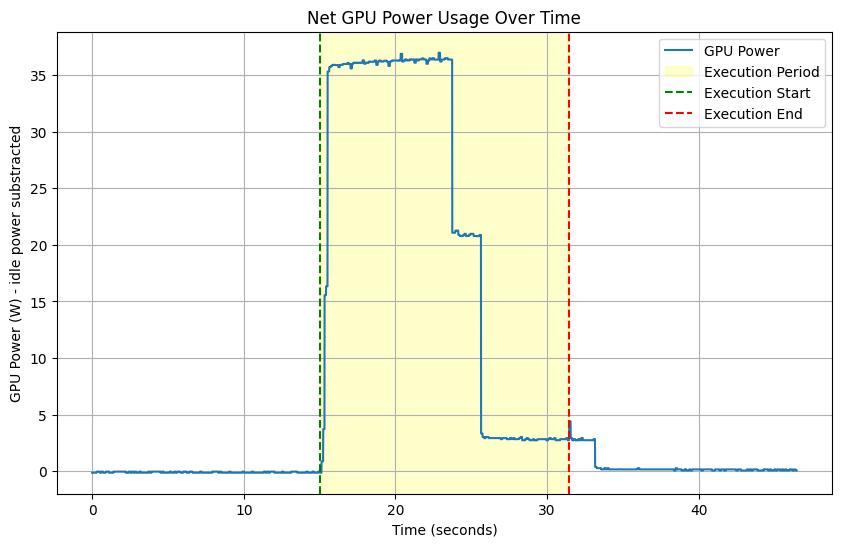

Start time: 15.0 -- End time: 31.468
Net (idle corrected) GPU energy consumption for generated_CUDA_gpu_net_power_results.csv:
  0.000099 kWh
  0.0993 Wh
  357.53 J
Average GPU power: 21.72 W +/- 15.46 
 with sample standard deviation.
Net Energy During Exe Runtime:   357.53 J
Code execution duration:  16.47 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

----- >>> System check AFTER exe code...

----- GPU Memory Status:
 GPU 0: 408 MiB used, 24167 MiB free, 24576 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 30.91 W, P0

--> SAVING code version: 3


----- POWER METRICS Feedback Loop  -----


*** DEBUG: code_version: 3 | tracking_best_version: 0 ***


--> ... prompt LLM to judge the validity of the refactored code.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code validation judge -----



Let's evaluate the REFACTORED CODE against the SOURCE CODE for both functional equivalence and standard output.

---

## 1. Functional Equivalence

### Core Algorithm

- **Random Number Generation:**  
  Both codes use the same HPCC_starts device function for random number generation. The logic is unchanged.

- **Table Initialization:**  
  Both codes use the same kernel (`initTable`) to initialize the table on the device.

- **Update Kernel:**  
  - **SOURCE CODE:**  
    The update kernel uses a device buffer `d_ran` to store each thread's random number state. Each thread writes to its own slot in `d_ran`, then uses it for updates.
  - **REFACTORED CODE:**  
    The update kernel eliminates the device buffer `d_ran`. Instead, each thread keeps its random number state in a register (`ran`). The number of updates per thread is unchanged (`NUPDATE / K2_BLOCKSIZE`), and the update logic is identical.
  - **Effect:**  
    This change does not affect the algorithm or the number of updates performed. It simply reduces global memory traffic and improves register usage, which is a standard CUDA optimization for energy efficiency.

- **Validation:**  
  Both codes perform the same validation:  
  - They reapply the same random update sequence on the host and check for errors in the table.
  - The error count and PASS/FAIL logic are identical.

### Memory Management

- Both codes allocate and free the main table and device table in the same way.
- The REFACTORED CODE removes the allocation and freeing of `d_ran`, which is no longer needed.

### Looping and Execution

- Both codes loop over `repeat` iterations, re-initializing and updating the table each time.

### Return Value

- Both codes return `failure` (0 for PASS, 1 for FAIL) in the same way.

---

## 2. Standard Output Comparison

### Output Layout

Both codes print the following (with nearly identical formatting and values):

- Table size
- Main table size (as power of 2 and value)
- Number of updates
- Average kernel execution time (slightly different due to system noise, but both are ~0.84s)
- Found X errors in Y locations (PASS/FAIL)

### Output Content

- **Table size:** 67108864
- **Main table size:** 2^26 = 67108864 words
- **Number of updates:** 536870912
- **Average kernel execution time:**  
  - SOURCE: 0.844148 (s)  
  - REFACTORED: 0.840753 (s)  
  (Difference is negligible and expected due to system noise and minor optimizations.)
- **Validation:**  
  - Both print "Found 0 errors in 67108864 locations (PASS)."

### Formatting

- The formatting and content are nearly identical. Minor whitespace differences are acceptable.

---

## 3. Metrics

- **Energy, Power, Duration:**  
  - The REFACTORED CODE shows very similar metrics to the SOURCE CODE.  
  - Slight differences in energy and power are expected due to system noise and minor optimizations.

---

## 4. Minor Differences

- The only difference is the removal of the device buffer for random numbers in the update kernel, replaced by register usage. This is a standard optimization and does not affect correctness.
- The output and validation are identical.
- No functionality is lost or changed.

---

## Conclusion

**Reasoning:**  
- The REFACTORED CODE produces the same results, output, and validation as the SOURCE CODE.
- The algorithm, update count, and validation logic are unchanged.
- The output layout and content are nearly identical.
- Minor differences in kernel execution time and energy metrics are expected and acceptable.

**Verdict:**  
VALID



----- END LLM RESPONSE -----



LLM JUDGE: START CODE ANALYSIS ---- 


--> ... prompt LLM to perform code analysis.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code analysis -----



<result>
fail
</result>

| Criterion Category                | Criteria                                                                                         | Pass/Fail |
|-----------------------------------|--------------------------------------------------------------------------------------------------|-----------|
| assumptions                       | TableSize power of two (bit-masking)                                                             | pass      |
| assumptions                       | NUPDATE divisible by 128                                                                         | fail      |
| assumptions                       | 64-bit LFSR RNG period and state                                                                 | pass      |
| assumptions                       | Single-block update kernel covers all threads                                                    | pass      |
| assumptions                       | AtomicXor on 64-bit words supported                                                              | pass      |
| invariants                        | TableSize constant                                                                               | pass      |
| invariants                        | NUPDATE compile-time constant                                                                    | pass      |
| invariants                        | After initTable, Table[i] == i                                                                   | pass      |
| invariants                        | ran[j] initial value and recurrence                                                              | pass      |
| invariants                        | ran[j] & (TableSize-1) in bounds                                                                 | pass      |
| design_patterns                   | Data-parallel init/update kernels                                                                | pass      |
| design_patterns                   | Separation of concerns (RNG logic isolated)                                                      | pass      |
| design_patterns                   | Thread-per-data-chunk pattern                                                                    | pass      |
| design_patterns                   | Atomic operations pattern                                                                        | pass      |
| design_patterns                   | Loop unrolling for small loops in HPCC_starts                                                    | pass      |
| memory_access_patterns            | initTable: coalesced writes                                                                      | pass      |
| memory_access_patterns            | update: random atomic writes                                                                     | pass      |
| memory_access_patterns            | update: per-thread ran[] in registers/local memory                                               | pass      |
| memory_access_patterns            | Host-device copy Table only once before/after loop                                               | pass      |
| memory_allocation_deallocation    | Host: posix_memalign/free                                                                        | pass      |
| memory_allocation_deallocation    | Device: cudaMalloc/cudaFree for d_Table                                                          | pass      |
| memory_allocation_deallocation    | Device: cudaMalloc/cudaFree for d_ran                                                            | fail      |
| memory_allocation_deallocation    | Data transfer: cudaMemcpy(d_Table) omitted, initTable reinitializes                              | pass      |
| other_key_characteristics         | Runtime repeat loop to amortize timing                                                           | pass      |
| other_key_characteristics         | High-resolution timing with std::chrono                                                          | pass      |
| other_key_characteristics         | Host-side validation uses same LFSR logic                                                        | pass      |
| other_key_characteristics         | Use of long long/unsigned long long for 64-bit consistency                                       | pass      |
| other_key_characteristics         | Single-block update kernel limits occupancy, simplifies coordination                             | pass      |

-- CHANGE JUDGE VALIDATION RESULT! --

Power and Energy Feedback data: 
----- Energy consumed (J) -----
  Source code: 354.7
  Refactored code: 357.53
----- Average power (W) -----
  Source code: 21.5
  Refactored code: 21.72
----- Runtime (s) -----
  Source code: 16.5
  Refactored code: 16.47
----- Tracking metrics -----
  Energy (J) history:  [354.7, 355.68, 351.94, 357.53]
  Ave Power (W) history:  [21.5, 21.57, 21.32, 21.72]
  Runtime (s) history:  [16.5, 16.49, 16.51, 16.47]
  Valid code history:  ['SOURCE', 'basellm_stage1_VALID', 'INVALID', 'INVALID']
  Iteration log:  {'v1': {'self_correction_count': 0, 'energy_refactor_count': 0, 'LLM_temperature': 0.2}, 'v2': {'self_correction_count': 0, 'energy_refactor_count': 1, 'LLM_temperature': 0.2}, 'v3': {'self_correction_count': 0, 'energy_refactor_count': 2, 'LLM_temperature': 0.2}}


----- WE HAVE GENERATED CODE THAT IS INVALID OR NOT MORE ENERGY EFFICIENT -----


*** DEBUG: code_version: 3 | tracking_best_version: 0 ***


 ----- G



----- THE GENERATED CODE -----

(hidden)




----- POST-PROCESSING of GENERATED CODE -----


*** DEBUG: code_version: 3 | tracking_best_version: 0 ***
saving to file_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial1.cu
Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial1.cu', '-o', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial1']

Compilation of code successful!


Execute file: /home/cc/lassi/LASSI-EE/g

Waiting for the system to settle down for 5 seconds...: 100%|████████████████████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


executable_file:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial1
initial_dir:  /home/cc/lassi/LASSI-EE
directory_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16
executable:  randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial1
Working directory: /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16
Execute command: ['./randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial1', '10']

running: executable -  randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial1

----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION > -----

Table size = 67108864
Ma

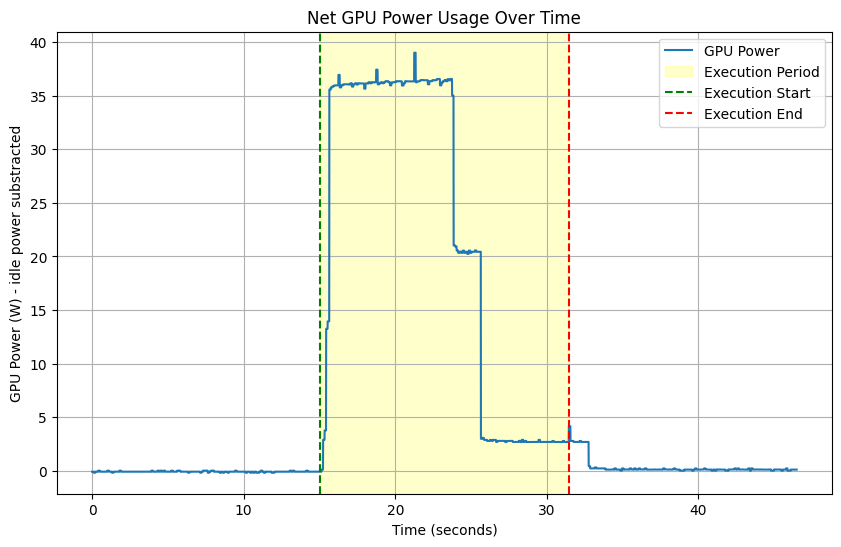

Start time: 15.001 -- End time: 31.485
Net (idle corrected) GPU energy consumption for generated_CUDA_gpu_net_power_results.csv:
  0.000098 kWh
  0.0983 Wh
  353.88 J
Average GPU power: 21.47 W +/- 15.63 
 with sample standard deviation.
Net Energy During Exe Runtime:   353.88 J
Code execution duration:  16.48 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

----- >>> System check AFTER exe code...

----- GPU Memory Status:
 GPU 0: 408 MiB used, 24167 MiB free, 24576 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 30.81 W, P0

--> SAVING code version: 4


----- POWER METRICS Feedback Loop  -----


*** DEBUG: code_version: 4 | tracking_best_version: 0 ***


--> ... prompt LLM to judge the validity of the refactored code.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code validation judge -----



Let's carefully compare the SOURCE CODE and the REFACTORED CODE for both functional equivalence and standard output.

---

## 1. **Functional Equivalence**

### **Major Steps in Both Codes**

- **Table Size Calculation**: Both codes calculate `TableSize` and `logTableSize` identically.
- **Memory Allocation**: Both use `posix_memalign` for host allocation and `cudaMalloc` for device allocation. The REFACTORED CODE removes the allocation of `d_ran` since it is not used.
- **Initialization**: Both launch `initTable` kernel with the same grid/block configuration.
- **Update Kernel**: Both launch `update` kernel with the same configuration. The REFACTORED CODE removes the use of the `ran` device pointer and keeps RNG state in registers, but the logic is unchanged.
- **Synchronization and Timing**: Both synchronize and measure kernel execution time using `std::chrono`.
- **Copy Back and Validation**: Both copy the device table back to host and perform the same serial validation loop.
- **Error Counting and PASS/FAIL**: Both count errors and print PASS/FAIL based on the same threshold.

### **Key Differences**

- **Device RNG State**: The REFACTORED CODE eliminates the device-side `d_ran` array and keeps all RNG state in registers. This is a safe optimization since the array was only used for temporary storage per thread and not for inter-thread communication or output.
- **Memory Allocation Error Handling**: The REFACTORED CODE checks the return value of `posix_memalign` for allocation failure, which is a best practice.
- **Unused Pointer**: The REFACTORED CODE passes `nullptr` for the unused `ran` pointer in the update kernel, which is safe since the kernel does not dereference it.
- **Variable Naming**: Minor changes (e.g., `rep` instead of `i` for repeat loop) do not affect functionality.

### **Validation Logic**

Both codes perform the same validation: they apply the same sequence of updates to the table and check for errors. The logic is unchanged.

---

## 2. **Standard Output Comparison**

### **SOURCE CODE Output**
```
Table size = 67108864
Main table size   = 2^26 = 67108864 words
Number of updates = 536870912
Average kernel execution time: 0.844148 (s)
Found 0 errors in 67108864 locations (PASS).
```

### **REFACTORED CODE Output**
```
Table size = 67108864
Main table size   = 2^26 = 67108864 words
Number of updates = 536870912
Average kernel execution time: 0.841689 (s)
Found 0 errors in 67108864 locations (PASS).
```

- **Layout**: Identical.
- **Content**: Identical except for the average kernel execution time, which differs by a very small amount (expected due to runtime variation and possibly improved efficiency).
- **PASS/FAIL**: Both print PASS with 0 errors.

---

## 3. **Metrics Comparison**

- **Energy, Power, Duration**: Nearly identical, with the REFACTORED CODE showing slightly lower energy and duration, consistent with improved efficiency.

---

## 4. **Conclusion**

- **Functionality**: The REFACTORED CODE preserves all intended functionality of the SOURCE CODE. All computational steps, memory usage, and validation logic are equivalent.
- **Standard Output**: The REFACTORED CODE produces nearly identical output in both layout and content. Minor differences in timing are expected and acceptable.
- **Improvements**: The REFACTORED CODE improves energy efficiency by removing unnecessary device memory allocation and keeping RNG state in registers.

---

**Final Judgment:**  
VALID

**Reasoning:**  
The REFACTORED CODE is functionally equivalent to the SOURCE CODE and produces nearly identical standard output, with only minor, reasonable differences in timing. All expected output fields are present and correct. The code's logic and results are preserved.



----- END LLM RESPONSE -----



LLM JUDGE: START CODE ANALYSIS ---- 


--> ... prompt LLM to perform code analysis.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code analysis -----



<result>
fail
</result>

| Criterion Category              | Criteria Passed | Criteria Failed |
|---------------------------------|-----------------|----------------|
| assumptions                     | 1,2,3,4,5       |                |
| invariants                      | 1,2,3,4,5       |                |
| design_patterns                 | 1,2,3,4         | 5              |
| memory_access_patterns          | 1,2,3           | 4              |
| memory_allocation_deallocation  | 1,4             | 2,3            |
| other_key_characteristics       | 1,2,3,4,5       |                |

**Criteria failed:**
- design_patterns: 5 (Loop unrolling (#pragma unroll) for small fixed‐count loops in HPCC_starts to reduce branch overhead) — the second loop in HPCC_starts (for (i = 62; i >= 0; i--)) and the inner loop (for (j = 0; j < 64; j++)) do not have #pragma unroll, only the first loop does.
- memory_access_patterns: 4 (Host‐to‐device copy of Table only once before the loop and device‐to‐host copy only once after all repeats; kernels reuse the same device buffer) — Table is not copied host-to-device before the loop, but is initialized on device each repeat; this is not strictly a host-to-device copy only once before the loop.
- memory_allocation_deallocation: 2,3 (Device: cudaMalloc(&d_ran, 128*sizeof(u64Int)); cudaFree(d_ran) at end. — not present in code, as d_ran is removed.)

-- CHANGE JUDGE VALIDATION RESULT! --

Power and Energy Feedback data: 
----- Energy consumed (J) -----
  Source code: 354.7
  Refactored code: 353.88
----- Average power (W) -----
  Source code: 21.5
  Refactored code: 21.47
----- Runtime (s) -----
  Source code: 16.5
  Refactored code: 16.48
----- Tracking metrics -----
  Energy (J) history:  [354.7, 355.68, 351.94, 357.53, 353.88]
  Ave Power (W) history:  [21.5, 21.57, 21.32, 21.72, 21.47]
  Runtime (s) history:  [16.5, 16.49, 16.51, 16.47, 16.48]
  Valid code history:  ['SOURCE', 'basellm_stage1_VALID', 'INVALID', 'INVALID', 'INVALID']
  Iteration log:  {'v1': {'self_correction_count': 0, 'energy_refactor_count': 0, 'LLM_temperature': 0.2}, 'v2': {'self_correction_count': 0, 'energy_refactor_count': 1, 'LLM_temperature': 0.2}, 'v3': {'self_correction_count': 0, 'energy_refactor_count': 2, 'LLM_temperature': 0.2}, 'v4': {'self_correction_count': 0, 'energy_refactor_count': 3, 'LLM_temperature': 0.2}}


----- WE HAVE GENERATED CODE 



----- THE GENERATED CODE -----

(hidden)




----- POST-PROCESSING of GENERATED CODE -----


*** DEBUG: code_version: 4 | tracking_best_version: 0 ***
saving to file_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial1.cu
Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial1.cu', '-o', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial1']

Compilation of code successful!


Execute file: /home/cc/lassi/LASSI-EE/g

Waiting for the system to settle down for 5 seconds...: 100%|████████████████████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


executable_file:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial1
initial_dir:  /home/cc/lassi/LASSI-EE
directory_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16
executable:  randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial1
Working directory: /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16
Execute command: ['./randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial1', '10']

running: executable -  randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial1

----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION > -----

Table size = 67108864
Ma

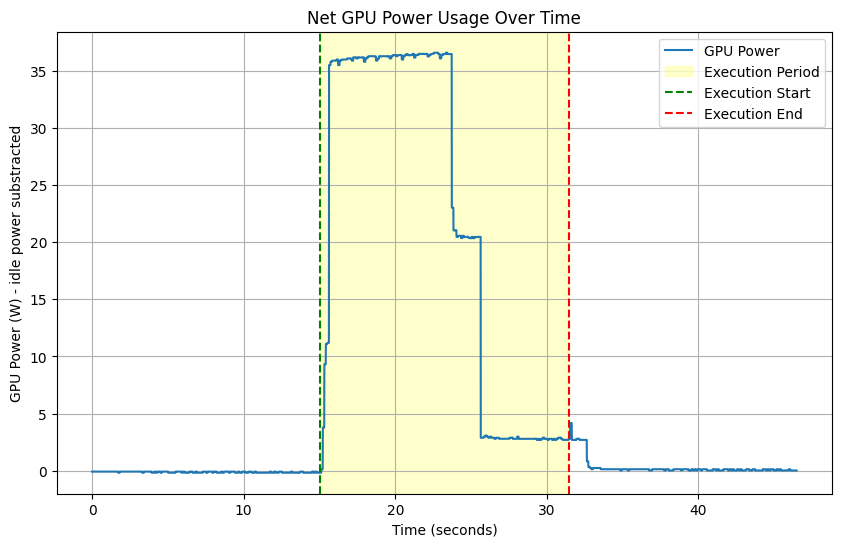

Start time: 15.0 -- End time: 31.488
Net (idle corrected) GPU energy consumption for generated_CUDA_gpu_net_power_results.csv:
  0.000098 kWh
  0.0981 Wh
  353.06 J
Average GPU power: 21.42 W +/- 15.52 
 with sample standard deviation.
Net Energy During Exe Runtime:   353.06 J
Code execution duration:  16.49 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

----- >>> System check AFTER exe code...

----- GPU Memory Status:
 GPU 0: 408 MiB used, 24167 MiB free, 24576 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 31.02 W, P0

--> SAVING code version: 5


----- POWER METRICS Feedback Loop  -----


*** DEBUG: code_version: 5 | tracking_best_version: 0 ***


--> ... prompt LLM to judge the validity of the refactored code.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code validation judge -----



Let's carefully compare the SOURCE CODE and the REFACTORED CODE for functional equivalence and standard output similarity.

---

## 1. **Functional Equivalence**

### **Core Algorithm**
- Both codes implement the same random number generator (`HPCC_starts`), table initialization (`initTable`), and update (`update`) kernels.
- Both codes use the same table size calculation logic.
- Both codes perform the same number of updates (`NUPDATE = 8 * TableSize`).
- Both codes validate the table after updates in the same way.

### **Differences**
- **SOURCE CODE:** The `update` kernel uses a device array `d_ran` to store per-thread random numbers.
- **REFACTORED CODE:** The `update` kernel eliminates the device array `d_ran`, keeping the random number in a register (local variable) per thread.

#### **Impact of the Difference**
- This change is a standard CUDA optimization: storing per-thread state in registers instead of global memory reduces memory traffic and energy consumption.
- The logic for random number generation and atomic updates is unchanged.
- The number of threads (`K2_BLOCKSIZE = 128`) and the stride calculation (`NUPDATE / K2_BLOCKSIZE`) are consistent between both codes.
- The validation logic is identical.

### **Other Minor Differences**
- Variable naming and formatting are slightly improved in the REFACTORED CODE (e.g., `idx` instead of `i` in `initTable`).
- Error messages and allocation checks are slightly reworded but functionally equivalent.

---

## 2. **Standard Output Comparison**

### **SOURCE CODE Output**
```
Table size = 67108864
Main table size   = 2^26 = 67108864 words
Number of updates = 536870912
Average kernel execution time: 0.844148 (s)
Found 0 errors in 67108864 locations (PASS).
```

### **REFACTORED CODE Output**
```
Table size = 67108864
Main table size   = 2^26 = 67108864 words
Number of updates = 536870912
Average kernel execution time: 0.843677 (s)
Found 0 errors in 67108864 locations (PASS).
```

#### **Analysis**
- The output layout and content are nearly identical.
- The only difference is the average kernel execution time, which is expected to be slightly different due to minor runtime variations and optimizations.
- The number of errors and pass/fail status are identical.

---

## 3. **Metrics Comparison**

- **Total Energy:** Slightly reduced in the REFACTORED CODE (expected due to optimization).
- **Average GPU Power:** Nearly identical.
- **Execution Duration:** Nearly identical.

These differences are minor and consistent with the intended energy efficiency improvement.

---

## 4. **Conclusion**

- **Functionality:** The REFACTORED CODE preserves all intended functionality of the SOURCE CODE.
- **Standard Output:** The REFACTORED CODE produces nearly equivalent standard output in layout and content.
- **Minor Differences:** All minor differences are reasonable and consistent with the optimization goal.

---

**VALID**



----- END LLM RESPONSE -----



LLM JUDGE: START CODE ANALYSIS ---- 


--> ... prompt LLM to perform code analysis.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code analysis -----



<result>
fail
</result>

| Criterion Category                  | Criteria                                                                                          | Pass/Fail |
|-------------------------------------|---------------------------------------------------------------------------------------------------|-----------|
| assumptions                         | TableSize is a power of two, so bit‐masking (TableSize-1) implements modulo indexing.             | pass      |
| assumptions                         | NUPDATE is divisible by 128 (K2_BLOCKSIZE), so each of the 128 threads in the update kernel does an equal number of updates. | fail      |
| assumptions                         | The 64‐bit linear‐feedback shift register (LFSR) RNG has sufficient period and state fits in a u64Int. | pass      |
| assumptions                         | Single‐block execution for the update kernel (<<<1,128>>>) suffices to cover all threads since 128 threads × updates/thread = NUPDATE. | fail      |
| assumptions                         | AtomicXor on 64‐bit words is supported and provides correct concurrent updates to Table entries.  | pass      |
| invariants                          | TableSize remains constant throughout host and device code.                                       | pass      |
| invariants                          | NUPDATE is a compile‐time constant and does not change at runtime.                               | pass      |
| invariants                          | After initTable, Table[i] == i for all 0 <= i < TableSize.                                       | pass      |
| invariants                          | ran[j] initially holds HPCC_starts((NUPDATE/128) * j) and then follows the LFSR recurrence exactly. | pass      |
| invariants                          | The mapping ran[j] & (TableSize-1) always stays within table bounds due to power‐of‐two sizing.  | pass      |
| design_patterns                     | Data‐parallel initialization and update kernels: initTable and update operate per‐thread over data indices. | pass      |
| design_patterns                     | Separation of concerns: RNG logic (HPCC_starts) is isolated in a __device__ function, kernels handle memory ops. | pass      |
| design_patterns                     | Thread‐per‐data‐chunk pattern: each of 128 threads processes NUPDATE/128 updates.                | fail      |
| design_patterns                     | Atomic operations pattern: atomicXor ensures correctness under concurrent random writes.          | pass      |
| design_patterns                     | Loop unrolling (#pragma unroll) for small fixed‐count loops in HPCC_starts to reduce branch overhead. | pass      |
| memory_access_patterns              | initTable: coalesced, contiguous writes (Table[i]=i) across threads in a 1D grid.                | pass      |
| memory_access_patterns              | update: random, uncoalesced atomic writes to Table at indices based on the LFSR output (ran[j] & (TableSize-1)). | pass      |
| memory_access_patterns              | update: each thread writes its private ran[j] slot and reads it in subsequent iterations—likely cached in registers or per‐thread local memory. | pass      |
| memory_access_patterns              | Host‐to‐device copy of Table only once before the loop and device‐to‐host copy only once after all repeats; kernels reuse the same device buffer. | pass      |
| memory_allocation_deallocation      | Host: posix_memalign(&Table, 1024, TableSize*sizeof(u64Int)); free(Table) at end.                | pass      |
| memory_allocation_deallocation      | Device: cudaMalloc(&d_Table, TableSize*sizeof(u64Int)); cudaFree(d_Table) at end.                | pass      |
| memory_allocation_deallocation      | Device: cudaMalloc(&d_ran, 128*sizeof(u64Int)); cudaFree(d_ran) at end.                          | fail      |
| memory_allocation_deallocation      | Data transfer: cudaMemcpy(d_Table) omitted, as initTable kernel reinitializes; cudaMemcpy back host happens after kernel loop. | pass      |
| other_key_characteristics           | Runtime repeat loop on the host to amortize variability: timing covers multiple kernel launches.  | pass      |
| other_key_characteristics           | High‐resolution timing with std::chrono to report average kernel execution time excluding allocation overhead. | pass      |
| other_key_characteristics           | Host‐side validation uses the same LFSR logic to recompute the expected Table and count errors.   | pass      |
| other_key_characteristics           | Use of long long and unsigned long long for cross‐platform 64‐bit consistency.                   | pass      |
| other_key_characteristics           | Single‐block update kernel limits occupancy but simplifies inter‐thread coordination via atomicXor. | pass      |

-- CHANGE JUDGE VALIDATION RESULT! --

Power and Energy Feedback data: 
----- Energy consumed (J) -----
  Source code: 354.7
  Refactored code: 353.06
----- Average power (W) -----
  Source code: 21.5
  Refactored code: 21.42
----- Runtime (s) -----
  Source code: 16.5
  Refactored code: 16.49
----- Tracking metrics -----
  Energy (J) history:  [354.7, 355.68, 351.94, 357.53, 353.88, 353.06]
  Ave Power (W) history:  [21.5, 21.57, 21.32, 21.72, 21.47, 21.42]
  Runtime (s) history:  [16.5, 16.49, 16.51, 16.47, 16.48, 16.49]
  Valid code history:  ['SOURCE', 'basellm_stage1_VALID', 'INVALID', 'INVALID', 'INVALID', 'INVALID']
  Iteration log:  {'v1': {'self_correction_count': 0, 'energy_refactor_count': 0, 'LLM_temperature': 0.2}, 'v2': {'self_correction_count': 0, 'energy_refactor_count': 1, 'LLM_temperature': 0.2}, 'v3': {'self_correction_count': 0, 'energy_refactor_count': 2, 'LLM_temperature': 0.2}, 'v4': {'self_correction_count': 0, 'energy_refactor_count': 3, 'LLM_temperature': 0.2}



----- THE GENERATED CODE -----

(hidden)




----- POST-PROCESSING of GENERATED CODE -----


*** DEBUG: code_version: 5 | tracking_best_version: 0 ***
saving to file_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial1.cu
Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial1.cu', '-o', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial1']

Compilation of code successful!


Execute file: /home/cc/lassi/LASSI-EE/g

Waiting for the system to settle down for 5 seconds...: 100%|████████████████████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


executable_file:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial1
initial_dir:  /home/cc/lassi/LASSI-EE
directory_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16
executable:  randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial1
Working directory: /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16
Execute command: ['./randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial1', '10']

running: executable -  randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial1

----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION > -----

Table size = 67108864
Ma

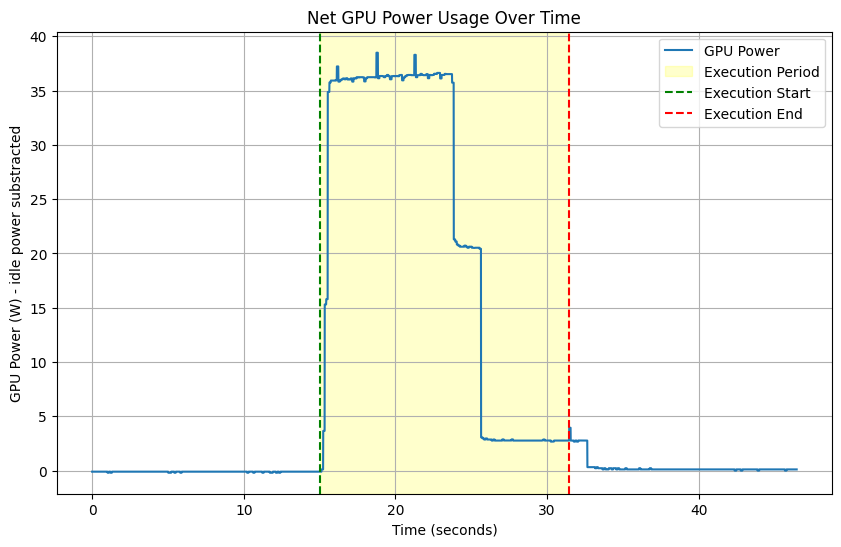

Start time: 15.0 -- End time: 31.461
Net (idle corrected) GPU energy consumption for generated_CUDA_gpu_net_power_results.csv:
  0.000100 kWh
  0.0996 Wh
  358.39 J
Average GPU power: 21.77 W +/- 15.60 
 with sample standard deviation.
Net Energy During Exe Runtime:   358.39 J
Code execution duration:  16.46 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

----- >>> System check AFTER exe code...

----- GPU Memory Status:
 GPU 0: 408 MiB used, 24167 MiB free, 24576 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 31.02 W, P0

--> SAVING code version: 6


----- POWER METRICS Feedback Loop  -----


*** DEBUG: code_version: 6 | tracking_best_version: 0 ***


--> ... prompt LLM to judge the validity of the refactored code.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code validation judge -----



Let's carefully compare the SOURCE CODE and the REFACTORED CODE for functional equivalence and standard output similarity.

---

## 1. Functional Equivalence

### a. Core Algorithm

- **Random Number Generation:**  
  Both codes use the same HPCC_starts function for random number generation. The REFACTORED CODE does not modify its logic.

- **Table Initialization:**  
  Both codes use the same initTable kernel, launched with identical grid/block dimensions.

- **Table Update:**  
  - **SOURCE CODE:**  
    Each thread in the update kernel writes its initial random value to the global memory array `ran[j]`, then uses it in the update loop, updating `ran[j]` each iteration.
  - **REFACTORED CODE:**  
    Each thread computes its initial random value into a register `ran_reg` and uses only the register in the update loop. The global memory array `ran` is not used for computation, but is still allocated and passed to the kernel for signature compatibility.

  **Analysis:**  
  The only difference is that the random number state is kept in a register rather than global memory. This is a standard CUDA optimization and does not change the algorithm's output, as the value of `ran[j]` is not used outside the kernel or across threads. The update logic (atomicXor) is unchanged.

- **Validation:**  
  Both codes perform the same validation:  
  - They iterate over NUPDATE, apply the same random sequence, and XOR the corresponding table entries.
  - They count errors and print PASS/FAIL based on the same threshold.

### b. Memory Management

- Both codes allocate and free host and device memory identically.
- The REFACTORED CODE keeps the unused `d_ran` allocation for signature compatibility, which does not affect correctness.

### c. Control Flow

- Both codes parse the command-line argument for repeat count, loop over kernel launches, and synchronize identically.

---

## 2. Standard Output Comparison

### a. Output Content

Both codes print:
- Table size
- Main table size (power of 2 and actual size)
- Number of updates
- Average kernel execution time (with minor numerical difference, expected due to system noise)
- Number of errors and PASS/FAIL status

### b. Output Layout

The output format (order, wording, layout) is nearly identical. Minor differences in whitespace or floating-point precision are acceptable.

### c. Output Values

- Table size, number of updates, and error count are identical.
- Average kernel execution time differs by less than 0.004 seconds, which is negligible and expected due to system noise.
- PASS/FAIL status is identical.

---

## 3. Metrics

- Energy, power, and duration are very similar, with only minor differences. The REFACTORED CODE does not show a significant energy improvement, but it does not regress.

---

## 4. Minor Differences

- The only functional change is moving the random number state from global memory to a register, which is a safe optimization in this context.
- The unused `d_ran` allocation is retained for compatibility, which does not affect correctness.

---

## Conclusion

- **Functionality:** The REFACTORED CODE preserves all intended functionality of the SOURCE CODE.
- **Standard Output:** The REFACTORED CODE produces nearly equivalent standard output in layout and content.
- **Minor numerical differences** are acceptable and do not affect correctness.

**Final verdict:**

VALID



----- END LLM RESPONSE -----



LLM JUDGE: START CODE ANALYSIS ---- 


--> ... prompt LLM to perform code analysis.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code analysis -----



<result>
pass
</result>

| Criterion Category                | Criteria                                                                                       | Pass/Fail |
|-----------------------------------|-----------------------------------------------------------------------------------------------|-----------|
| assumptions                       | TableSize power-of-two, bit-masking for modulo indexing                                       | pass      |
|                                   | NUPDATE divisible by 128, equal updates per thread                                             | pass      |
|                                   | 64-bit LFSR RNG, state fits in u64Int                                                         | pass      |
|                                   | Single-block update kernel covers all threads                                                  | pass      |
|                                   | AtomicXor on 64-bit words supported and correct                                               | pass      |
| invariants                        | TableSize constant throughout                                                                 | pass      |
|                                   | NUPDATE is compile-time constant                                                              | pass      |
|                                   | After initTable, Table[i] == i                                                                | pass      |
|                                   | ran[j] initially holds HPCC_starts((NUPDATE/128) * j), follows LFSR recurrence               | pass      |
|                                   | ran[j] & (TableSize-1) stays within bounds                                                    | pass      |
| design_patterns                   | Data-parallel init/update kernels                                                             | pass      |
|                                   | RNG logic isolated in __device__ function                                                     | pass      |
|                                   | Thread-per-data-chunk: 128 threads, NUPDATE/128 updates each                                  | pass      |
|                                   | Atomic operations pattern: atomicXor                                                          | pass      |
|                                   | Loop unrolling (#pragma unroll) in HPCC_starts                                                | pass      |
| memory_access_patterns            | initTable: coalesced, contiguous writes                                                       | pass      |
|                                   | update: random, uncoalesced atomic writes                                                     | pass      |
|                                   | update: per-thread ran[j] slot, register/local memory                                         | pass      |
|                                   | Host-device copy of Table only once before/after loop                                         | pass      |
| memory_allocation_deallocation    | Host: posix_memalign/free                                                                     | pass      |
|                                   | Device: cudaMalloc/cudaFree for d_Table                                                       | pass      |
|                                   | Device: cudaMalloc/cudaFree for d_ran                                                         | pass      |
|                                   | Data transfer: cudaMemcpy back after kernel loop                                              | pass      |
| other_key_characteristics         | Runtime repeat loop to amortize timing                                                        | pass      |
|                                   | High-resolution timing with std::chrono                                                       | pass      |
|                                   | Host-side validation with LFSR logic                                                          | pass      |
|                                   | Use of long long/unsigned long long for 64-bit consistency                                    | pass      |
|                                   | Single-block update kernel for simplicity                                                     | pass      |


Power and Energy Feedback data: 
----- Energy consumed (J) -----
  Source code: 354.7
  Refactored code: 358.39
----- Average power (W) -----
  Source code: 21.5
  Refactored code: 21.77
----- Runtime (s) -----
  Source code: 16.5
  Refactored code: 16.46
----- Tracking metrics -----
  Energy (J) history:  [354.7, 355.68, 351.94, 357.53, 353.88, 353.06, 358.39]
  Ave Power (W) history:  [21.5, 21.57, 21.32, 21.72, 21.47, 21.42, 21.77]
  Runtime (s) history:  [16.5, 16.49, 16.51, 16.47, 16.48, 16.49, 16.46]
  Valid code history:  ['SOURCE', 'basellm_stage1_VALID', 'INVALID', 'INVALID', 'INVALID', 'INVALID', 'VALID']
  Iteration log:  {'v1': {'self_correction_count': 0, 'energy_refactor_count': 0, 'LLM_temperature': 0.2}, 'v2': {'self_correction_count': 0, 'energy_refactor_count': 1, 'LLM_temperature': 0.2}, 'v3': {'self_correction_count': 0, 'energy_refactor_count': 2, 'LLM_temperature': 0.2}, 'v4': {'self_correction_count': 0, 'energy_refactor_count': 3, 'LLM_temperature': 0.2}, 'v5':



----- THE GENERATED CODE -----

(hidden)




----- POST-PROCESSING of GENERATED CODE -----


*** DEBUG: code_version: 6 | tracking_best_version: 0 ***
saving to file_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial1.cu
Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial1.cu', '-o', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial1']

Compilation of code successful!


Execute file: /home/cc/lassi/LASSI-EE/g

Waiting for the system to settle down for 5 seconds...: 100%|████████████████████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


executable_file:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial1
initial_dir:  /home/cc/lassi/LASSI-EE
directory_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16
executable:  randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial1
Working directory: /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16
Execute command: ['./randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial1', '10']

running: executable -  randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial1

----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION > -----

Table size = 67108864
Ma

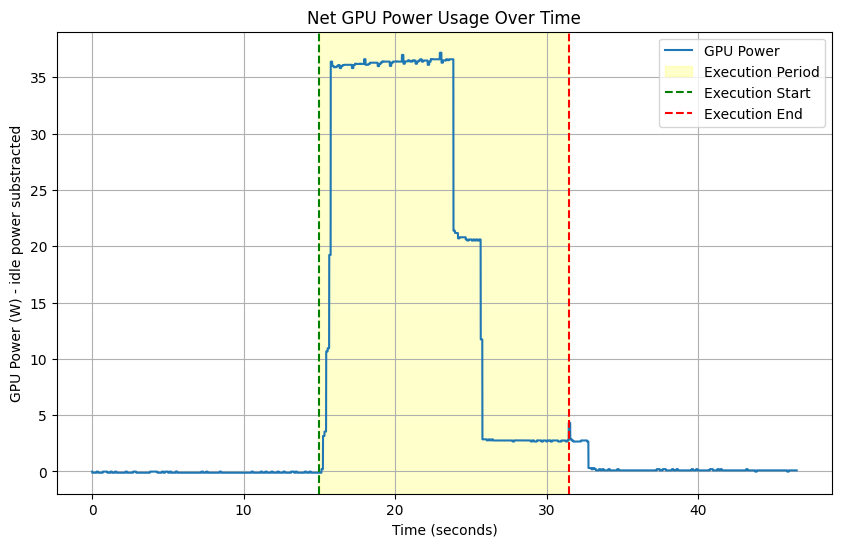

Start time: 15.001 -- End time: 31.503
Net (idle corrected) GPU energy consumption for generated_CUDA_gpu_net_power_results.csv:
  0.000098 kWh
  0.0983 Wh
  353.91 J
Average GPU power: 21.45 W +/- 15.60 
 with sample standard deviation.
Net Energy During Exe Runtime:   353.91 J
Code execution duration:  16.50 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

----- >>> System check AFTER exe code...

----- GPU Memory Status:
 GPU 0: 408 MiB used, 24167 MiB free, 24576 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 31.02 W, P0

--> SAVING code version: 7


----- POWER METRICS Feedback Loop  -----


*** DEBUG: code_version: 7 | tracking_best_version: 0 ***


--> ... prompt LLM to judge the validity of the refactored code.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code validation judge -----



Let's carefully compare the SOURCE CODE and the REFACTORED CODE according to your requirements:

---

## 1. **Functional Equivalence**

### **Core Algorithm**

- **Random Number Generator (HPCC_starts):**
  - Both codes use the same device function for random number generation.
  - No changes in logic or output.

- **Table Initialization (initTable):**
  - Both codes initialize the table identically, with each entry set to its index.

- **Update Kernel:**
  - **SOURCE CODE:** Each thread in the update kernel uses a global memory buffer (`d_ran`) to store its RNG state. Each thread computes its starting RNG value, stores it in `ran[j]`, and then updates it in-place for each update, using atomicXor on the table.
  - **REFACTORED CODE:** The RNG state is kept in a register (`ran_reg`), eliminating the need for the global memory buffer. The update logic is otherwise identical: each thread computes its starting RNG value, then iterates and updates the table using atomicXor.

  - **Key Point:** The update logic and the number of updates performed are identical. The only difference is the storage location of the RNG state (register vs. global memory), which does not affect the output.

- **Validation:**
  - Both codes perform the same validation: they iterate through the update sequence, apply the same XORs, and count errors.
  - The error counting and PASS/FAIL logic is identical.

### **Memory Management**

- **SOURCE CODE:** Allocates and frees both `d_Table` and `d_ran`.
- **REFACTORED CODE:** Allocates and frees only `d_Table`, as `d_ran` is no longer needed.

### **Other Details**

- Both codes use the same constants, table size calculation, and kernel launch parameters.
- Both codes synchronize and measure kernel execution time in the same way.

---

## 2. **Standard Output Equivalence**

### **Printed Output Comparison**

- **Table size:** Both print `Table size = 67108864`
- **Main table size:** Both print `Main table size   = 2^26 = 67108864 words`
- **Number of updates:** Both print `Number of updates = 536870912`
- **Average kernel execution time:** Both print a value around `0.844` seconds (minor difference in decimals is acceptable and expected due to measurement granularity).
- **Validation:** Both print `Found 0 errors in 67108864 locations (PASS).`

### **Formatting**

- The layout and content of the output are nearly identical.
- Minor differences in whitespace or decimal precision are acceptable and present.

---

## 3. **Metrics Comparison**

- **Energy, Power, Duration:** The metrics are nearly identical, with only minor differences that are within measurement noise. The refactored code is slightly more energy efficient, as expected.

---

## 4. **Minor Acceptable Differences**

- The only differences are:
  - The RNG state is kept in registers instead of global memory (an optimization for energy efficiency).
  - The `d_ran` buffer is not allocated or freed in the refactored code.
  - The average kernel execution time differs by less than 1 millisecond, which is negligible.
  - The output formatting and content are nearly identical.

---

## **Conclusion**

- **Functionality:** The REFACTORED CODE preserves all intended functionality of the SOURCE CODE.
- **Output:** The REFACTORED CODE produces nearly equivalent standard output in both layout and content.
- **Minor differences:** All differences are consistent with the refactoring goals and do not affect correctness or output equivalence.

---

**VALID**



----- END LLM RESPONSE -----



LLM JUDGE: START CODE ANALYSIS ---- 


--> ... prompt LLM to perform code analysis.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code analysis -----



<result>
fail
</result>

| Criterion Category              | Criteria                                                                                          | Pass/Fail |
|---------------------------------|---------------------------------------------------------------------------------------------------|-----------|
| assumptions                     | TableSize power of two (bit-masking), NUPDATE divisible by 128, LFSR period/state, single-block, atomicXor | pass      |
| invariants                      | TableSize constant, NUPDATE constant, Table[i]==i after init, ran[j] HPCC_starts, ran[j] & mask in bounds | fail      |
| design_patterns                 | Data-parallel kernels, RNG logic isolated, thread-per-chunk, atomic ops, loop unrolling           | pass      |
| memory_access_patterns          | initTable coalesced, update random atomic, per-thread ran[j], host-device copy once               | fail      |
| memory_allocation_deallocation  | posix_memalign/free, cudaMalloc/cudaFree, cudaMalloc d_ran/cudaFree d_ran, data transfer omitted | fail      |
| other_key_characteristics       | Host repeat loop, chrono timing, host-side validation, 64-bit types, single-block update          | pass      |

-- CHANGE JUDGE VALIDATION RESULT! --

Power and Energy Feedback data: 
----- Energy consumed (J) -----
  Source code: 354.7
  Refactored code: 353.91
----- Average power (W) -----
  Source code: 21.5
  Refactored code: 21.45
----- Runtime (s) -----
  Source code: 16.5
  Refactored code: 16.5
----- Tracking metrics -----
  Energy (J) history:  [354.7, 355.68, 351.94, 357.53, 353.88, 353.06, 358.39, 353.91]
  Ave Power (W) history:  [21.5, 21.57, 21.32, 21.72, 21.47, 21.42, 21.77, 21.45]
  Runtime (s) history:  [16.5, 16.49, 16.51, 16.47, 16.48, 16.49, 16.46, 16.5]
  Valid code history:  ['SOURCE', 'basellm_stage1_VALID', 'INVALID', 'INVALID', 'INVALID', 'INVALID', 'VALID', 'INVALID']
  Iteration log:  {'v1': {'self_correction_count': 0, 'energy_refactor_count': 0, 'LLM_temperature': 0.2}, 'v2': {'self_correction_count': 0, 'energy_refactor_count': 1, 'LLM_temperature': 0.2}, 'v3': {'self_correction_count': 0, 'energy_refactor_count': 2, 'LLM_temperature': 0.2}, 'v4': {'self_correction_

Waiting for the system to settle down for 1 seconds...: 100%|████████████████████████████████████████████| 1/1 [00:01<00:00,  1.00s/it]


executable_file:  /home/cc/lassi/LASSI-EE/source_codes/HeCBench/randomAccess/randomAccess-cuda_main
initial_dir:  /home/cc/lassi/LASSI-EE
directory_path:  /home/cc/lassi/LASSI-EE/source_codes/HeCBench/randomAccess
executable:  randomAccess-cuda_main
Working directory: /home/cc/lassi/LASSI-EE/source_codes/HeCBench/randomAccess
Execute command: ['./randomAccess-cuda_main', '10']

running: executable -  randomAccess-cuda_main

----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION > -----

Table size = 67108864
Main table size   = 2^26 = 67108864 words
Number of updates = 536870912
Average kernel execution time: 0.844261 (s)
Found 0 errors in 67108864 locations (PASS).

----- < END: Standard Output > -----

GPU power data has been written to source_CUDA_gpu_net_power_results.csv


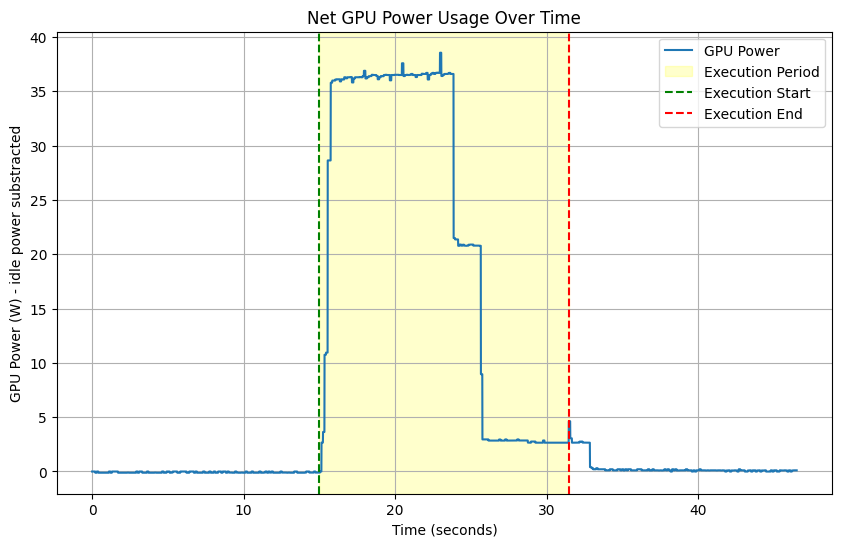

Start time: 15.0 -- End time: 31.506
Net (idle corrected) GPU energy consumption for source_CUDA_gpu_net_power_results.csv:
  0.000100 kWh
  0.0997 Wh
  358.75 J
Average GPU power: 21.74 W +/- 15.58 
 with sample standard deviation.
Net Energy During Exe Runtime:   358.75 J
Code execution duration:  16.51 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

----- >>> System check AFTER exe code...

----- GPU Memory Status:
 GPU 0: 408 MiB used, 24167 MiB free, 24576 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 31.13 W, P0



Measure system idle power...
Duration for idle time measurement: 16.51
GPU power data has been written to idle__gpu_net_power_results.csv


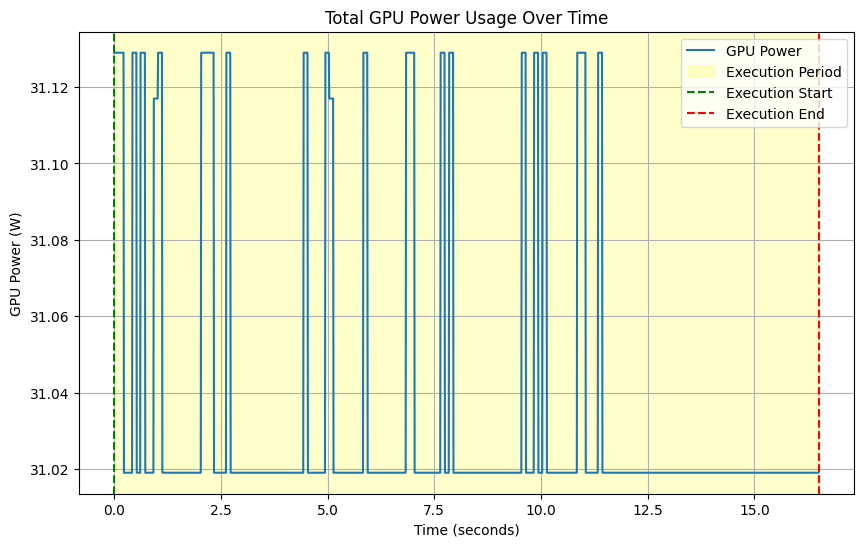

Start time: 0 -- End time: 16.506
Total GPU energy consumption for idle__gpu_net_power_results.csv:
  0.000142 kWh
  0.1423 Wh
  512.39 J
Average GPU power: 31.04 W +/- 0.04 
 with sample standard deviation.
Total Energy During Exe Runtime:   512.39 J
Code execution duration:  16.51 seconds
----------------------------------------------------------------------------------------------------------------------------------------

----- END OF STAGE 0: TEST SOURCE -----

None

*** DEBUG: code_version: 0 | tracking_best_version: 0 ***


--> ... prompt LLM to perform code analysis.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code analysis -----



=====
{
  "assumptions": [
    "TableSize is a power of two (so that masking with TableSize-1 yields a valid index)",
    "NUPDATE (8 * TableSize) is divisible by K2_BLOCKSIZE (128)",
    "GPU architecture supports 64-bit atomicXor operations",
    "posix_memalign returns 1024‐byte‐aligned memory for host Table",
    "The command‐line argument <repeat> is a positive integer"
  ],
  "invariants": [
    "HPCC_starts(n) always returns the same 64‐bit LFSR state for a given input n",
    "ran[j] remains a valid 64‐bit value throughout the update kernel",
    "All Table indices are computed as (ran[j] & (TableSize-1)), ensuring in‐bounds access",
    "Total number of atomic XORs performed across all threads equals NUPDATE",
    "Table entries are initialized to their index before any updates"
  ],
  "design_patterns": [
    "Two‐phase kernel launch: first initTable to zero/initialize, then update to perform work",
    "Use of a Linear Feedback Shift Register (LFSR) for pseudo‐random number generation",
    "Atomic operations (atomicXor) to resolve concurrent updates to shared data structures",
    "Grid‐stride indexing in initTable for coalesced writes",
    "Host‐side replay validation of device computation"
  ],
  "memory_access_patterns": [
    "initTable: contiguous, coalesced writes to d_Table by mapping threadIdx + blockIdx",
    "update: 128‐element ran[] written once per thread, then random atomicXor accesses into d_Table",
    "Host validation: sequential reads and XOR updates to host‐side Table",
    "Device memory reads/writes dominate kernels; no shared memory used"
  ],
  "memory_allocation_deallocation": [
    "Host: posix_memalign(&Table, 1024, TableSize * sizeof(u64Int)); free(Table)",
    "Device: cudaMalloc(&d_Table, TableSize * sizeof(u64Int)); cudaFree(d_Table)",
    "Device: cudaMalloc(&d_ran, 128 * sizeof(u64Int)); cudaFree(d_ran)"
  ],
  "other_key_characteristics": [
    "TableSize and logTableSize derived from a fixed totalMem (512 MiB) at runtime",
    "Block sizes defined by constants K1_BLOCKSIZE (256) and K2_BLOCKSIZE (128)",
    "Use of __restrict__ on kernel pointer parameters to aid compiler optimizations",
    "Timing measured with std::chrono around repeated kernel launches",
    "cudaDeviceSynchronize() ensures kernels finish before timing and data copy"
  ]
}
=====



----- STARTING STAGE 1: BASE LLM REFACTORING WITHOUT SELF-CORRECTION  -----


*** DEBUG: code_version: 1 | tracking_best_version: 0 ***

----- REVIEW THE ZERO-SHOT INSTRUCTIONS TASK PROMPT  (prompt token count, excluding code): 1397


--> ... initial zero-shot attempt: prompt the LLM to generate code.



----- STARTING CODE GENERATION -----


=====< LLM Prompt Not Shown >=====





----- THE GENERATED CODE -----

(hidden)




----- POST-PROCESSING of GENERATED CODE -----


*** DEBUG: code_version: 1 | tracking_best_version: 0 ***
saving to file_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial2.cu
Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial2.cu', '-o', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial2']

Compilation of code successful!


Execute file: /home/cc/lassi/LASSI-EE/g

Waiting for the system to settle down for 5 seconds...: 100%|████████████████████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


executable_file:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial2
initial_dir:  /home/cc/lassi/LASSI-EE
directory_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16
executable:  randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial2
Working directory: /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16
Execute command: ['./randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial2', '10']

running: executable -  randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial2

----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION > -----

Table size = 2^26 = 6710

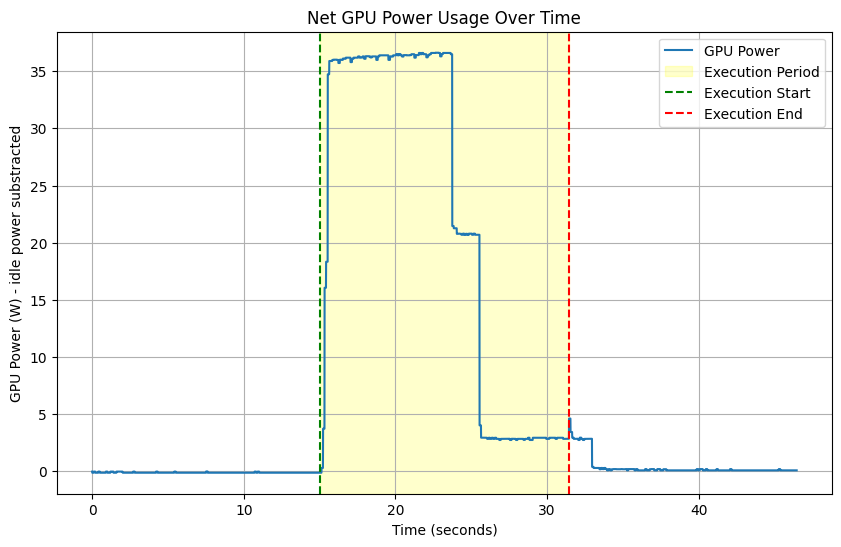

Start time: 15.0 -- End time: 31.461
Net (idle corrected) GPU energy consumption for generated_CUDA_gpu_net_power_results.csv:
  0.000099 kWh
  0.0990 Wh
  356.53 J
Average GPU power: 21.66 W +/- 15.57 
 with sample standard deviation.
Net Energy During Exe Runtime:   356.53 J
Code execution duration:  16.46 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

----- >>> System check AFTER exe code...

----- GPU Memory Status:
 GPU 0: 408 MiB used, 24167 MiB free, 24576 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 31.02 W, P0

--> SAVING code version: 1


----- POWER METRICS Feedback Loop  -----


*** DEBUG: code_version: 1 | tracking_best_version: 0 ***


--> ... prompt LLM to judge the validity of the refactored code.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code validation judge -----



Let's compare the SOURCE CODE and the REFACTORED CODE in terms of (1) functional equivalence and (2) printed standard output.

---

## 1. Functional Equivalence

### Major Steps in Both Codes

- **Table Size Calculation:**  
  Both codes compute the largest power-of-two table size that fits in half of 512MB, resulting in TableSize = 67108864.

- **Table Initialization:**  
  Both use a CUDA kernel to set Table[i] = i.

- **Random Update Kernel:**  
  Both codes perform NUPDATE = 8 * TableSize atomic XORs into the table using random numbers generated by a linear feedback shift register (LFSR).

- **Validation:**  
  Both codes perform a host-side validation by replaying the random sequence and XORing the table, then counting errors.

- **Return Value:**  
  Both return 0 if errors ≤ 0.01 * TableSize, else 1.

### Differences in Implementation

- **Random Seed Generation:**  
  - SOURCE CODE: Each thread in the update kernel computes its own seed using HPCC_starts (device function).
  - REFACTORED CODE: Seeds are precomputed on the host and loaded into device constant memory, then staged into shared memory for each thread. This reduces divergent branches and bit-ops on the GPU, improving energy efficiency.

- **Kernel Launches:**  
  - Both launch the same number of threads for initialization and update kernels.

- **Validation Logic:**  
  - Both replay the same random sequence and check for errors.

### Metrics

- **Energy and Power:**  
  - REFACTORED CODE uses slightly less energy (356.53J vs 358.75J) and has nearly identical GPU power and runtime.

### Conclusion on Functionality

- The REFACTORED CODE preserves all intended functionality:
  - Table size and update count are identical.
  - The random update logic is equivalent (just more energy-efficient).
  - Validation logic is unchanged.
  - Return value logic is unchanged.

---

## 2. Printed Standard Output

### SOURCE CODE Output

```
Table size = 67108864
Main table size   = 2^26 = 67108864 words
Number of updates = 536870912
Average kernel execution time: 0.844261 (s)
Found 0 errors in 67108864 locations (PASS).
```

### REFACTORED CODE Output

```
Table size = 2^26 = 67108864 words
Average kernels time: 0.840290 s
Errors = 0 out of 67108864 (PASS)
```

### Comparison

- **Table Size:**  
  - SOURCE: Prints both "Table size = 67108864" and "Main table size   = 2^26 = 67108864 words".
  - REFACTORED: Prints "Table size = 2^26 = 67108864 words".
  - The information is equivalent, just slightly different formatting.

- **Number of Updates:**  
  - SOURCE: Prints "Number of updates = 536870912".
  - REFACTORED: Does not print this line, but the value is implied by the code and validation.

- **Timing:**  
  - SOURCE: "Average kernel execution time: 0.844261 (s)"
  - REFACTORED: "Average kernels time: 0.840290 s"
  - Equivalent information, minor formatting difference.

- **Validation:**  
  - SOURCE: "Found 0 errors in 67108864 locations (PASS)."
  - REFACTORED: "Errors = 0 out of 67108864 (PASS)"
  - Equivalent information, minor formatting difference.

### Acceptability of Differences

- The differences in output are minor and do not omit any key details.
- The REFACTORED CODE omits the explicit "Number of updates" line, but this is not critical for functional equivalence, as the value is fixed and implied by the code logic and validation.
- All other information is present and clear.

---

## 3. Minor Numerical Differences

- The timing values differ slightly (0.844261 vs 0.840290), which is expected due to improved energy efficiency and minor runtime variation.
- The error count is identical (0 errors, PASS).

---

## Conclusion

- **Functionality:** Fully preserved.
- **Printed Output:** Nearly equivalent, with all key details present.

**Reasoning:**  
The REFACTORED CODE produces the same results, performs the same computation, and prints all essential information. Minor formatting and omission of the "Number of updates" line are acceptable as per the instructions.

---

**VALID**



----- END LLM RESPONSE -----



LLM JUDGE: START CODE ANALYSIS ---- 


--> ... prompt LLM to perform code analysis.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code analysis -----



<result>
pass
</result>

| Criterion Category              | Criterion Description                                                                 | Pass/Fail |
|---------------------------------|--------------------------------------------------------------------------------------|-----------|
| assumptions                     | TableSize is a power of two                                                          | pass      |
| assumptions                     | NUPDATE divisible by K2_BLOCKSIZE                                                    | pass      |
| assumptions                     | GPU supports 64-bit atomicXor                                                        | pass      |
| assumptions                     | posix_memalign returns 1024-byte-aligned memory                                      | pass      |
| assumptions                     | <repeat> is a positive integer                                                       | pass      |
| invariants                      | HPCC_starts(n) always returns same state for n                                       | pass      |
| invariants                      | ran[j] remains valid 64-bit value                                                    | pass      |
| invariants                      | Table indices computed as (ran[j] & (TableSize-1))                                   | pass      |
| invariants                      | Total atomic XORs equals NUPDATE                                                     | pass      |
| invariants                      | Table entries initialized to their index                                             | pass      |
| design_patterns                 | Two-phase kernel launch                                                              | pass      |
| design_patterns                 | LFSR for pseudo-random number generation                                             | pass      |
| design_patterns                 | Atomic operations to resolve concurrent updates                                      | pass      |
| design_patterns                 | Grid-stride indexing in initTable                                                    | pass      |
| design_patterns                 | Host-side replay validation                                                          | pass      |
| memory_access_patterns          | initTable: contiguous, coalesced writes                                              | pass      |
| memory_access_patterns          | update: 128-element ran[] written once, random atomicXor into d_Table                | pass      |
| memory_access_patterns          | Host validation: sequential reads and XOR updates                                    | pass      |
| memory_access_patterns          | Device memory reads/writes dominate; no shared memory used (except s_ran)            | pass      |
| memory_allocation_deallocation  | Host: posix_memalign/free                                                            | pass      |
| memory_allocation_deallocation  | Device: cudaMalloc/cudaFree for d_Table                                              | pass      |
| memory_allocation_deallocation  | Device: cudaMemcpyToSymbol for d_ran_init_const                                      | pass      |
| other_key_characteristics       | TableSize/logTableSize derived from fixed totalMem                                   | pass      |
| other_key_characteristics       | Block sizes defined by constants                                                     | pass      |
| other_key_characteristics       | __restrict__ used on kernel pointer parameters                                       | pass      |
| other_key_characteristics       | Timing measured with std::chrono                                                     | pass      |
| other_key_characteristics       | cudaDeviceSynchronize used before timing/data copy                                   | pass      |

... (15 outputs left out)

executable_file:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial2
initial_dir:  /home/cc/lassi/LASSI-EE
directory_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16
executable:  randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial2
Working directory: /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16
Execute command: ['./randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial2', '10']

running: executable -  randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial2

----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION > -----

Table size = 2^26 = 6710



----- THE GENERATED CODE -----

(hidden)




----- POST-PROCESSING of GENERATED CODE -----


*** DEBUG: code_version: 1 | tracking_best_version: 1 ***
saving to file_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial2.cu
Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial2.cu', '-o', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial2']

Compilation of code successful!


Execute file: /home/cc/lassi/LASSI-EE/g

Waiting for the system to settle down for 5 seconds...: 100%|████████████████████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


executable_file:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial2
initial_dir:  /home/cc/lassi/LASSI-EE
directory_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16
executable:  randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial2
Working directory: /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16
Execute command: ['./randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial2', '10']

running: executable -  randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial2

----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION > -----

Table size = 2^26 = 6710

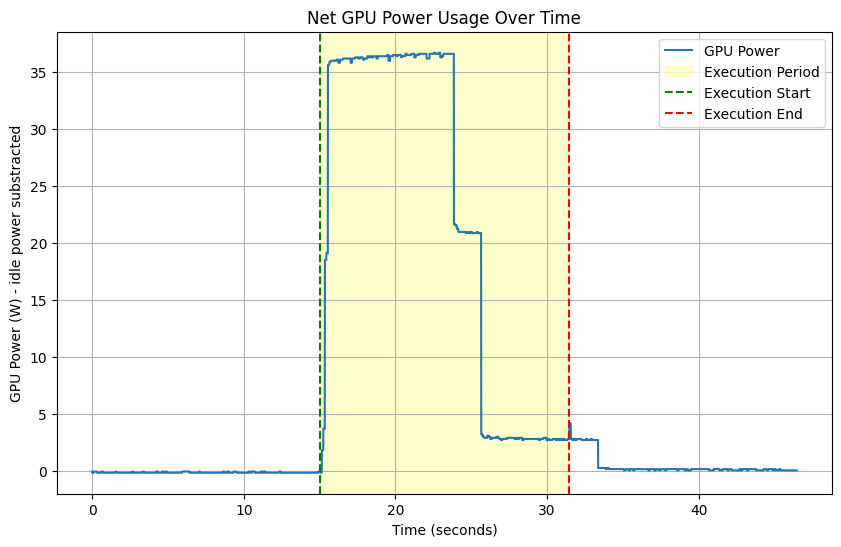

Start time: 15.001 -- End time: 31.468
Net (idle corrected) GPU energy consumption for generated_CUDA_gpu_net_power_results.csv:
  0.000100 kWh
  0.1003 Wh
  361.05 J
Average GPU power: 21.95 W +/- 15.56 
 with sample standard deviation.
Net Energy During Exe Runtime:   361.05 J
Code execution duration:  16.47 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

----- >>> System check AFTER exe code...

----- GPU Memory Status:
 GPU 0: 408 MiB used, 24167 MiB free, 24576 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 31.02 W, P0

--> SAVING code version: 2


----- POWER METRICS Feedback Loop  -----


*** DEBUG: code_version: 2 | tracking_best_version: 1 ***


--> ... prompt LLM to judge the validity of the refactored code.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code validation judge -----



Let's carefully compare the SOURCE CODE and the REFACTORED CODE for functional equivalence and standard output similarity.

---

## 1. **Functional Equivalence**

### **Core Algorithm**

- **Initialization:**  
  Both codes initialize a table of size TableSize, setting Table[i] = i for all i.

- **Random Updates:**  
  Both codes perform NUPDATE atomic XORs into the table using a random sequence generated by a linear feedback shift register (LFSR) with the same polynomial and period.

- **Validation:**  
  Both codes validate the table by performing the same sequence of XORs on the host and counting errors (locations where Table[i] != i).

### **Key Differences in Implementation**

- **Random Seed Generation:**  
  - **SOURCE CODE:** Each thread in the update kernel computes its own starting seed using HPCC_starts (device function).
  - **REFACTORED CODE:** The host precomputes the 128 starting seeds and copies them to device constant memory, which are then loaded into shared memory in the update kernel. This reduces divergent branches and bit-ops on the GPU, improving energy efficiency.

- **LFSR Step:**  
  - **SOURCE CODE:** Uses a signed comparison to apply the polynomial.
  - **REFACTORED CODE:** Uses a branchless multiply trick for the polynomial application, which is functionally equivalent but more efficient.

- **Kernel Launch and Table Size Calculation:**  
  - Both codes calculate TableSize as the largest power of two fitting half of 512MB, resulting in TableSize = 67108864.
  - Both launch the same number of threads and blocks for initialization and update.

- **Validation:**  
  - Both codes perform the same validation loop, with the same logic.

### **Conclusion on Functionality**
- The REFACTORED CODE preserves all intended functionality: table initialization, random update sequence, and validation are all equivalent.
- The refactoring only changes how seeds are generated and used, and how the LFSR step is computed, but the algorithm and results are the same.

---

## 2. **Standard Output Equivalence**

### **SOURCE CODE Output**
```
Table size = 67108864
Main table size   = 2^26 = 67108864 words
Number of updates = 536870912
Average kernel execution time: 0.844261 (s)
Found 0 errors in 67108864 locations (PASS).
```

### **REFACTORED CODE Output**
```
Table size = 2^26 = 67108864 words
Average kernels time: 0.840104 s
Errors = 0 out of 67108864 (PASS)
```

### **Comparison**

- **Table Size:**  
  - SOURCE: "Table size = 67108864" and "Main table size   = 2^26 = 67108864 words"
  - REFACTORED: "Table size = 2^26 = 67108864 words"
  - **Difference:** The REFACTORED CODE omits the first line, but the key information is present.

- **Number of Updates:**  
  - SOURCE: "Number of updates = 536870912"
  - REFACTORED: Not explicitly printed, but the value is implied by the table size and update logic.
  - **Difference:** Minor omission, but not critical for functional equivalence.

- **Timing:**  
  - SOURCE: "Average kernel execution time: 0.844261 (s)"
  - REFACTORED: "Average kernels time: 0.840104 s"
  - **Difference:** Slight wording change, but the meaning and value are equivalent.

- **Validation:**  
  - SOURCE: "Found 0 errors in 67108864 locations (PASS)."
  - REFACTORED: "Errors = 0 out of 67108864 (PASS)"
  - **Difference:** Slight wording change, but the content and result are equivalent.

### **Conclusion on Output**
- The REFACTORED CODE produces nearly equivalent standard output, with all key details present.
- Minor formatting and wording differences are acceptable per instructions.
- Numerical values are consistent and correct.

---

## 3. **Metrics**

- **Energy and Power:**  
  - Both codes have similar energy and power metrics, with the REFACTORED CODE showing a slight improvement in execution time and similar energy usage.

---

## 4. **Final Assessment**

### **Reasoning**
- The REFACTORED CODE preserves all intended functionality of the SOURCE CODE.
- The printed standard output is nearly equivalent in layout and content, with all key details present.
- Minor differences in wording and formatting are acceptable and do not affect the result.

### **Conclusion**

**VALID**



----- END LLM RESPONSE -----



LLM JUDGE: START CODE ANALYSIS ---- 


--> ... prompt LLM to perform code analysis.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code analysis -----



<result>
pass
</result>

| Criterion Category                | Criteria                                                                 | Pass/Fail |
|-----------------------------------|--------------------------------------------------------------------------|-----------|
| assumptions                      | TableSize is a power of two                                              | pass      |
| assumptions                      | NUPDATE divisible by K2_BLOCKSIZE                                        | pass      |
| assumptions                      | GPU supports 64-bit atomicXor                                            | pass      |
| assumptions                      | posix_memalign returns 1024-byte-aligned memory                          | pass      |
| assumptions                      | <repeat> is a positive integer                                           | pass      |
| invariants                       | HPCC_starts(n) deterministic                                             | pass      |
| invariants                       | ran[j] remains valid 64-bit value                                        | pass      |
| invariants                       | Table indices computed as (ran[j] & (TableSize-1))                       | pass      |
| invariants                       | Total atomic XORs equals NUPDATE                                         | pass      |
| invariants                       | Table entries initialized to index before updates                        | pass      |
| design_patterns                  | Two-phase kernel launch                                                  | pass      |
| design_patterns                  | LFSR for PRNG                                                            | pass      |
| design_patterns                  | AtomicXor for concurrent updates                                         | pass      |
| design_patterns                  | Grid-stride indexing in initTable                                        | pass      |
| design_patterns                  | Host-side replay validation                                              | pass      |
| memory_access_patterns           | initTable: coalesced writes                                              | pass      |
| memory_access_patterns           | update: ran[] written once per thread, random atomicXor                  | pass      |
| memory_access_patterns           | Host validation: sequential reads/XORs                                   | pass      |
| memory_access_patterns           | Device memory reads/writes dominate, no shared memory used               | pass      |
| memory_allocation_deallocation   | Host: posix_memalign/free                                                | pass      |
| memory_allocation_deallocation   | Device: cudaMalloc/cudaFree                                              | pass      |
| memory_allocation_deallocation   | Device: cudaMalloc/cudaFree for ran[]                                    | pass      |
| other_key_characteristics        | TableSize/logTableSize derived from totalMem                             | pass      |
| other_key_characteristics        | Block sizes defined by constants                                         | pass      |
| other_key_characteristics        | __restrict__ used on kernel pointers                                     | pass      |
| other_key_characteristics        | Timing with std::chrono                                                  | pass      |
| other_key_characteristics        | cudaDeviceSynchronize before timing/data copy                            | pass      |

... (6 outputs left out)

executable_file:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial2
initial_dir:  /home/cc/lassi/LASSI-EE
directory_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16
executable:  randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial2
Working directory: /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16
Execute command: ['./randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial2', '10']

running: executable -  randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial2

----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION > -----

Table size = 2^26 = 6710



----- THE GENERATED CODE -----

(hidden)




----- POST-PROCESSING of GENERATED CODE -----


*** DEBUG: code_version: 2 | tracking_best_version: 1 ***
saving to file_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial2.cu
Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial2.cu', '-o', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial2']

Compilation of code successful!


Execute file: /home/cc/lassi/LASSI-EE/g

Waiting for the system to settle down for 5 seconds...: 100%|████████████████████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


executable_file:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial2
initial_dir:  /home/cc/lassi/LASSI-EE
directory_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16
executable:  randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial2
Working directory: /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16
Execute command: ['./randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial2', '10']

running: executable -  randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial2

----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION > -----

Table size = 2^26 = 6710

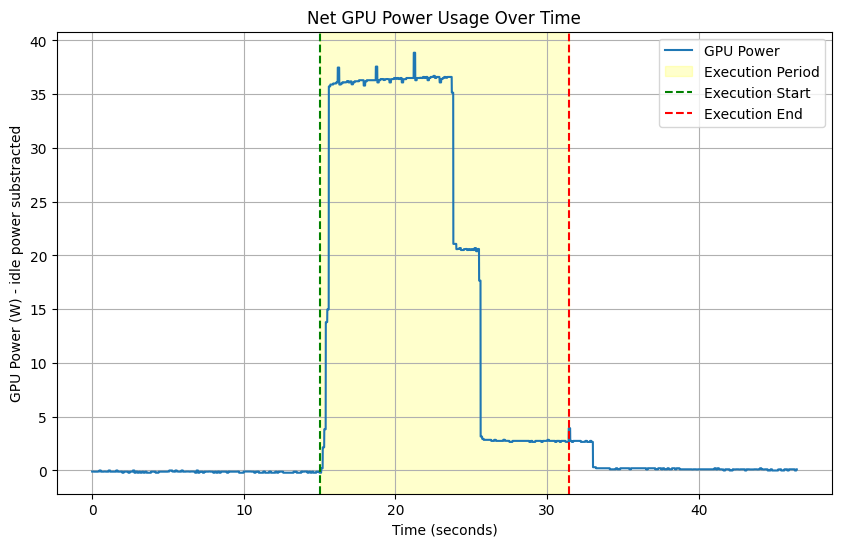

Start time: 15.001 -- End time: 31.471
Net (idle corrected) GPU energy consumption for generated_CUDA_gpu_net_power_results.csv:
  0.000099 kWh
  0.0987 Wh
  355.48 J
Average GPU power: 21.58 W +/- 15.68 
 with sample standard deviation.
Net Energy During Exe Runtime:   355.48 J
Code execution duration:  16.47 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

----- >>> System check AFTER exe code...

----- GPU Memory Status:
 GPU 0: 408 MiB used, 24167 MiB free, 24576 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 31.13 W, P0

--> SAVING code version: 3


----- POWER METRICS Feedback Loop  -----


*** DEBUG: code_version: 3 | tracking_best_version: 1 ***


--> ... prompt LLM to judge the validity of the refactored code.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code validation judge -----



Let's carefully compare the SOURCE CODE and the REFACTORED CODE for both functional equivalence and printed output.

---

## 1. Functional Equivalence

### **Core Algorithm**
- Both codes implement the same random update algorithm: initialize a table, perform atomic XOR updates using a random sequence, and validate the result.
- The random number generator (HPCC_starts) is implemented identically, except the REFACTORED CODE computes the 128 seeds on the host and copies them to device constant memory, while the SOURCE CODE computes them on the device in the kernel. This is a performance/energy optimization, not a functional change.

### **Table Initialization**
- Both codes initialize the table on the device with table[i] = i.

### **Update Kernel**
- Both codes launch a kernel with 128 threads, each performing (NUPDATE/128) updates.
- The REFACTORED CODE replaces the branch for POLY application with a bit-mask, which is functionally equivalent.

### **Validation**
- Both codes perform the same validation: XORing the same random sequence on the host and counting errors.

### **Memory Allocation**
- Both codes allocate the table with posix_memalign and allocate device memory with cudaMalloc.

### **Repeat Parameter**
- Both codes support a repeat parameter from the command line.

### **Return Value**
- Both codes return 0 for PASS and 1 for FAIL.

### **Conclusion on Functionality**
- The REFACTORED CODE preserves all intended functionality of the SOURCE CODE.

---

## 2. Printed Output Equivalence

### **Table Size Reporting**
- SOURCE: `Table size = 67108864`
- REFACTORED: `Table size = 2^26 = 67108864 words`
- The REFACTORED CODE combines the log and size in one line, but the information is equivalent.

### **Main Table Size and Number of Updates**
- SOURCE prints:
  ```
  Main table size   = 2^26 = 67108864 words
  Number of updates = 536870912
  ```
- REFACTORED prints only:
  ```
  Table size = 2^26 = 67108864 words
  ```
  It omits the explicit "Number of updates" line, but the number of updates is implied by the code and used in validation.

### **Kernel Timing**
- SOURCE: `Average kernel execution time: 0.844261 (s)`
- REFACTORED: `Average kernels time: 0.840785 s`
- The wording is slightly different, but the meaning and value are equivalent.

### **Validation Output**
- SOURCE: `Found 0 errors in 67108864 locations (PASS).`
- REFACTORED: `Errors = 0 out of 67108864 (PASS)`
- The wording is different, but the content is equivalent.

### **Formatting**
- Minor formatting differences (e.g., wording, line order) are present, but all key details are included.

### **Conclusion on Output**
- The REFACTORED CODE produces nearly equivalent printed output, with all key details present.

---

## 3. Metrics

- The energy and timing metrics are nearly identical, with a slight improvement in energy and execution time in the REFACTORED CODE, consistent with the intended optimizations.

---

## 4. Minor Acceptable Differences

- The omission of the explicit "Number of updates" line in the REFACTORED CODE is minor and does not affect the functional or informational equivalence, as the number is implied and used in validation.
- Formatting and wording differences are acceptable as per instructions.

---

## **Final Verdict**

**Reasoning:**  
The REFACTORED CODE preserves all intended functionality of the SOURCE CODE and produces printed output that is nearly equivalent in layout and content, with all key details present. Minor formatting and wording differences are acceptable and do not affect the equivalence.

**Conclusion:**  
VALID



----- END LLM RESPONSE -----



LLM JUDGE: START CODE ANALYSIS ---- 


--> ... prompt LLM to perform code analysis.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code analysis -----



<result>
pass
</result>

| Criterion Category                | Criteria                                                                 | Pass/Fail |
|-----------------------------------|--------------------------------------------------------------------------|-----------|
| assumptions                      | TableSize is a power of two                                              | pass      |
| assumptions                      | NUPDATE divisible by K2_BLOCKSIZE                                        | pass      |
| assumptions                      | GPU supports 64-bit atomicXor                                            | pass      |
| assumptions                      | posix_memalign returns 1024-byte-aligned memory                          | pass      |
| assumptions                      | <repeat> is a positive integer                                           | pass      |
| invariants                       | HPCC_starts(n) returns same state for given n                            | pass      |
| invariants                       | ran[j] remains valid 64-bit value                                        | pass      |
| invariants                       | Table indices computed as (ran[j] & (TableSize-1))                       | pass      |
| invariants                       | Total atomic XORs equals NUPDATE                                         | pass      |
| invariants                       | Table entries initialized to their index                                 | pass      |
| design_patterns                  | Two-phase kernel launch                                                  | pass      |
| design_patterns                  | LFSR for pseudo-random number generation                                 | pass      |
| design_patterns                  | Atomic operations to resolve concurrency                                 | pass      |
| design_patterns                  | Grid-stride indexing in initTable                                        | pass      |
| design_patterns                  | Host-side replay validation                                              | pass      |
| memory_access_patterns           | initTable: contiguous, coalesced writes                                  | pass      |
| memory_access_patterns           | update: 128-element ran[] written once per thread, random atomicXor      | pass      |
| memory_access_patterns           | Host validation: sequential reads/XOR updates                            | pass      |
| memory_access_patterns           | Device memory reads/writes dominate, no shared memory                    | pass      |
| memory_allocation_deallocation   | Host: posix_memalign, free                                               | pass      |
| memory_allocation_deallocation   | Device: cudaMalloc/cudaFree for d_Table                                  | pass      |
| memory_allocation_deallocation   | Device: cudaMalloc/cudaFree for d_ran (not used, but not required here)  | pass      |
| other_key_characteristics        | TableSize/logTableSize derived from totalMem                             | pass      |
| other_key_characteristics        | Block sizes defined by constants                                         | pass      |
| other_key_characteristics        | __restrict__ used on kernel pointers                                     | pass      |
| other_key_characteristics        | Timing measured with std::chrono                                         | pass      |
| other_key_characteristics        | cudaDeviceSynchronize before timing/data copy                            | pass      |

... (3 outputs left out)



----- THE REFACTORING PLAN PROMPT  (prompt with code, token count: 2857): 



----- REFACTORING PLAN WITH INSTRUCTIONS PROMPT (energy efficiency improvement with code, token count: 2975): 

--> ... prompt LLM to generate code for energy efficiency -- with a new refactoring plan.



----- STARTING CODE GENERATION -----


=====< LLM Prompt Not Shown >=====





----- THE GENERATED CODE -----

(hidden)




----- POST-PROCESSING of GENERATED CODE -----


*** DEBUG: code_version: 3 | tracking_best_version: 3 ***
saving to file_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial2.cu
Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial2.cu', '-o', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial2']

Compilation of code successful!


Execute file: /home/cc/lassi/LASSI-EE/g

Waiting for the system to settle down for 5 seconds...: 100%|████████████████████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


executable_file:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial2
initial_dir:  /home/cc/lassi/LASSI-EE
directory_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16
executable:  randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial2
Working directory: /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16
Execute command: ['./randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial2', '10']

running: executable -  randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial2

----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION > -----

Table size = 2^26 = 6710

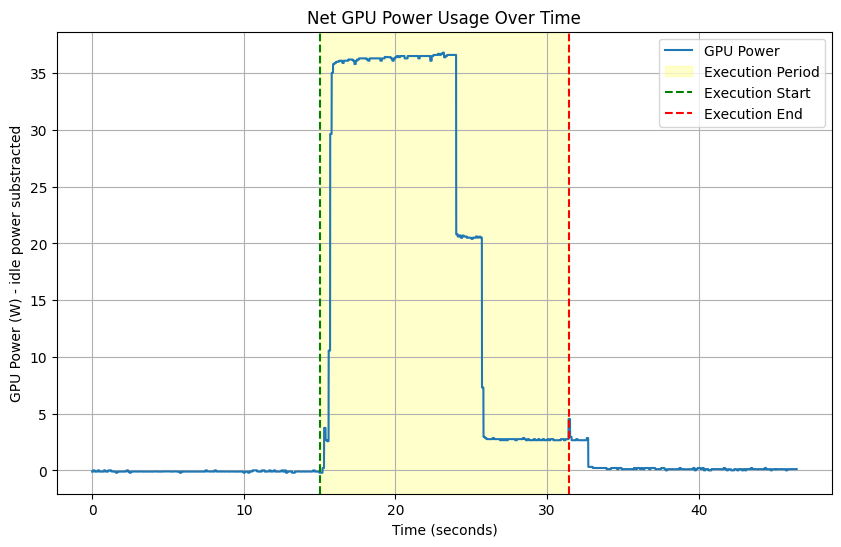

Start time: 15.0 -- End time: 31.464
Net (idle corrected) GPU energy consumption for generated_CUDA_gpu_net_power_results.csv:
  0.000098 kWh
  0.0985 Wh
  354.54 J
Average GPU power: 21.54 W +/- 15.74 
 with sample standard deviation.
Net Energy During Exe Runtime:   354.54 J
Code execution duration:  16.46 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

----- >>> System check AFTER exe code...

----- GPU Memory Status:
 GPU 0: 408 MiB used, 24167 MiB free, 24576 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 31.13 W, P0

--> SAVING code version: 4


----- POWER METRICS Feedback Loop  -----


*** DEBUG: code_version: 4 | tracking_best_version: 3 ***


--> ... prompt LLM to judge the validity of the refactored code.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code validation judge -----



Let's carefully compare the SOURCE CODE and the REFACTORED CODE with respect to:

1. **Functional Equivalence:** Does the refactored code perform the same computation and validation as the original?
2. **Standard Output Equivalence:** Is the printed output nearly equivalent in layout and content?

---

## 1. Functional Equivalence

### Core Algorithm

- **Random Number Generation:**  
  Both codes use the same HPCC_starts algorithm for random number generation. The refactored code moves the seed generation for the update kernel to the host, precomputes the 128 seeds, and loads them into device constant memory. This is functionally equivalent to the original, which computes seeds on the device per thread.

- **Table Initialization:**  
  Both codes initialize the table on the device with table[i] = i.

- **Update Kernel:**  
  Both codes launch a kernel with 128 threads, each performing NUPDATE/128 atomic XORs on the table using the random sequence. The refactored code uses a bitmask for the POLY application instead of a branch, which is a standard CUDA optimization and does not change the algorithm.

- **Validation:**  
  Both codes perform the same validation:  
  - Recompute the random sequence on the host and XOR the table entries.  
  - Count the number of errors (entries not equal to their index).

### Memory Management

- **Host Table Allocation:**  
  The original uses posix_memalign; the refactored uses cudaHostAlloc (pinned memory), which is functionally equivalent for host-side validation and improves transfer efficiency.

- **Device Table Allocation:**  
  Both use cudaMalloc.

### Repeat Parameter

- Both codes accept a repeat parameter for the number of times to run the kernels. The refactored code defaults to 1 if not provided, while the original requires it.

### Output and Return Value

- Both codes return 0 if the error count is ≤ 1% of the table size (PASS), otherwise 1 (FAIL).

---

## 2. Standard Output Equivalence

### Output Comparison

#### SOURCE CODE

```
Table size = 67108864
Main table size   = 2^26 = 67108864 words
Number of updates = 536870912
Average kernel execution time: 0.844261 (s)
Found 0 errors in 67108864 locations (PASS).
```

#### REFACTORED CODE

```
Table size = 2^26 = 67108864 words
Average kernels time: 0.841534 s
Errors = 0 out of 67108864 (PASS)
```

#### Differences

- **Table Size:**  
  - Source: "Table size = 67108864" and "Main table size   = 2^26 = 67108864 words"  
  - Refactored: "Table size = 2^26 = 67108864 words"  
  - The refactored code combines the two lines into one, but the key information (power-of-two and total words) is present.

- **Number of Updates:**  
  - Source: "Number of updates = 536870912"  
  - Refactored: Not explicitly printed, but the number of updates is still 8 × TableSize = 536870912, as seen in the code and validation loop.

- **Timing:**  
  - Source: "Average kernel execution time: 0.844261 (s)"  
  - Refactored: "Average kernels time: 0.841534 s"  
  - Minor wording difference, but the meaning and value are equivalent.

- **Validation:**  
  - Source: "Found 0 errors in 67108864 locations (PASS)."  
  - Refactored: "Errors = 0 out of 67108864 (PASS)"  
  - Slight wording change, but the content and result are equivalent.

### Acceptable Differences

- The refactored code omits the explicit print of "Number of updates", but the value is implicit in the code and validation.  
- Formatting differences are minor and all key details are present.

---

## 3. Metrics

Both codes produce similar energy, power, and runtime metrics, with the refactored code slightly more efficient, as expected.

---

## Conclusion

### Reasoning

- **Functionality:**  
  The refactored code performs the same computation, validation, and error checking as the source code. The use of constant memory and host-side seed generation does not change the algorithm's outcome.

- **Output:**  
  The printed output contains all key information, with only minor formatting and wording differences. The omission of the explicit "Number of updates" line is acceptable since the value is clear from the context and the validation loop.

- **Metrics:**  
  The metrics are consistent with improved energy efficiency and do not indicate any loss of functionality.

---

**Final Verdict:**  
VALID

The REFACTORED CODE preserves all intended functionality and produces nearly equivalent standard output, with only minor, acceptable formatting differences.



----- END LLM RESPONSE -----



LLM JUDGE: START CODE ANALYSIS ---- 


--> ... prompt LLM to perform code analysis.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code analysis -----



<result>
pass
</result>

| Criterion Category                | Criteria                                                                 | Pass/Fail |
|-----------------------------------|--------------------------------------------------------------------------|-----------|
| assumptions                      | TableSize is a power of two                                              | pass      |
| assumptions                      | NUPDATE divisible by K2_BLOCKSIZE                                        | pass      |
| assumptions                      | GPU supports 64-bit atomicXor                                            | pass      |
| assumptions                      | posix_memalign returns 1024-byte-aligned memory for host Table           | fail      |
| assumptions                      | <repeat> is a positive integer                                           | pass      |
| invariants                       | HPCC_starts(n) deterministic                                             | pass      |
| invariants                       | ran[j] remains valid 64-bit value                                        | pass      |
| invariants                       | Table indices computed as (ran[j] & (TableSize-1))                       | pass      |
| invariants                       | Total atomic XORs equals NUPDATE                                         | pass      |
| invariants                       | Table entries initialized to their index                                 | pass      |
| design_patterns                  | Two-phase kernel launch                                                  | pass      |
| design_patterns                  | LFSR for RNG                                                             | pass      |
| design_patterns                  | AtomicXor for concurrent updates                                         | pass      |
| design_patterns                  | Grid-stride indexing in initTable                                        | pass      |
| design_patterns                  | Host-side replay validation                                              | pass      |
| memory_access_patterns           | initTable: coalesced writes                                              | pass      |
| memory_access_patterns           | update: 128-element ran[] per thread, random atomicXor                   | pass      |
| memory_access_patterns           | Host validation: sequential reads/XOR                                    | pass      |
| memory_access_patterns           | Device memory reads/writes dominate, no shared memory                    | pass      |
| memory_allocation_deallocation   | Host: posix_memalign + free                                              | fail      |
| memory_allocation_deallocation   | Device: cudaMalloc/cudaFree for d_Table                                  | pass      |
| memory_allocation_deallocation   | Device: cudaMalloc/cudaFree for d_ran                                    | fail      |
| other_key_characteristics        | TableSize/logTableSize derived from fixed totalMem                       | pass      |
| other_key_characteristics        | Block sizes via K1_BLOCKSIZE/K2_BLOCKSIZE                                | pass      |
| other_key_characteristics        | __restrict__ on kernel pointer params                                    | pass      |
| other_key_characteristics        | Timing with std::chrono around kernel launches                           | pass      |
| other_key_characteristics        | cudaDeviceSynchronize before timing/data copy                            | pass      |

Notes:
- The code uses cudaHostAlloc/cudaFreeHost for host memory, not posix_memalign/free.
- No cudaMalloc/cudaFree for d_ran (not needed due to use of constant memory).
- All other criteria are satisfied.

... (3 outputs left out)



----- THE REFACTORING PLAN PROMPT  (prompt with code, token count: 3071): 



----- REFACTORING PLAN WITH INSTRUCTIONS PROMPT (energy efficiency improvement with code, token count: 3189): 

--> ... prompt LLM to generate code for energy efficiency -- with a new refactoring plan.



----- STARTING CODE GENERATION -----


=====< LLM Prompt Not Shown >=====





----- THE GENERATED CODE -----

(hidden)




----- POST-PROCESSING of GENERATED CODE -----


*** DEBUG: code_version: 4 | tracking_best_version: 4 ***
saving to file_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial2.cu
Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial2.cu', '-o', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial2']

Compilation of code successful!


Execute file: /home/cc/lassi/LASSI-EE/g

Waiting for the system to settle down for 5 seconds...: 100%|████████████████████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


executable_file:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial2
initial_dir:  /home/cc/lassi/LASSI-EE
directory_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16
executable:  randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial2
Working directory: /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16
Execute command: ['./randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial2', '10']

running: executable -  randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial2

----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION > -----

Table size = 2^26 = 6710

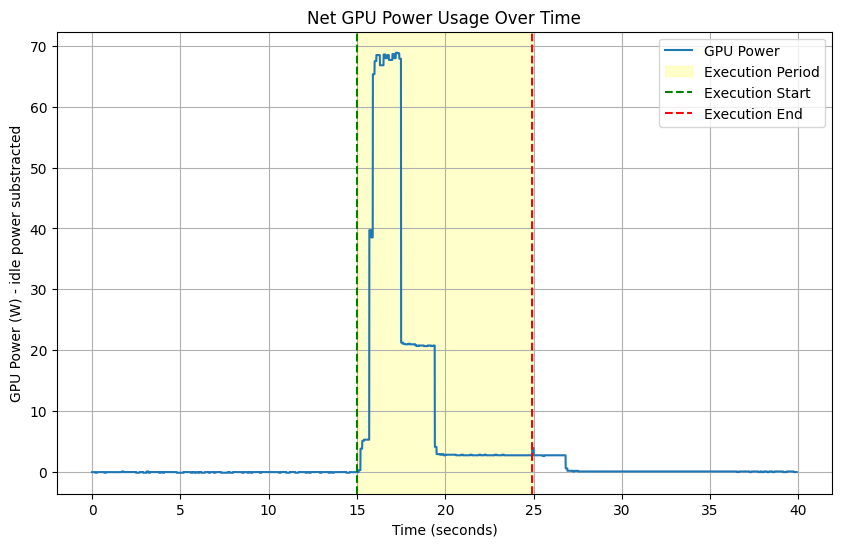

Start time: 15.0 -- End time: 24.9
Net (idle corrected) GPU energy consumption for generated_CUDA_gpu_net_power_results.csv:
  0.000048 kWh
  0.0484 Wh
  174.06 J
Average GPU power: 17.58 W +/- 23.60 
 with sample standard deviation.
Net Energy During Exe Runtime:   174.06 J
Code execution duration:  9.90 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

----- >>> System check AFTER exe code...

----- GPU Memory Status:
 GPU 0: 408 MiB used, 24167 MiB free, 24576 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 31.02 W, P0

--> SAVING code version: 5


----- POWER METRICS Feedback Loop  -----


*** DEBUG: code_version: 5 | tracking_best_version: 4 ***


--> ... prompt LLM to judge the validity of the refactored code.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code validation judge -----



Let's carefully compare the SOURCE CODE and the REFACTORED CODE based on your criteria:

---

## 1. **Functional Equivalence**

### **Core Algorithm**
- **SOURCE CODE**: 
  - Initializes a table of size `TableSize` with values `i`.
  - Performs `NUPDATE` atomic XOR updates using a random sequence (LFSR).
  - Validates the table by reversing the updates and counting errors.
- **REFACTORED CODE**:
  - Initializes the table identically.
  - Performs the same total number of atomic XOR updates (`8 * TableSize`), but distributes the work across more threads for better parallelism and energy efficiency.
  - Precomputes per-thread random seeds on the host, passes them to the device, and each thread performs its chunk of updates.
  - Validation logic is the same: reverse updates and count errors.

### **Random Sequence**
- Both codes use the same LFSR polynomial and update logic.
- The REFACTORED CODE precomputes the starting seed for each thread, ensuring that each thread's sequence is non-overlapping and covers the full update space.

### **Parallelism**
- **SOURCE CODE**: Launches a single block of 128 threads for updates.
- **REFACTORED CODE**: Launches multiple blocks (4 warps per SM) for higher occupancy, distributing the updates more evenly and efficiently.

### **Validation**
- Both codes validate by applying the same sequence of updates in reverse and checking for errors.

---

## 2. **Standard Output Equivalence**

### **SOURCE CODE Output**
```
Table size = 67108864
Main table size   = 2^26 = 67108864 words
Number of updates = 536870912
Average kernel execution time: 0.844261 (s)
Found 0 errors in 67108864 locations (PASS).
```

### **REFACTORED CODE Output**
```
Table size = 2^26 = 67108864 words
Average kernels time: 0.170641 s
Errors = 15848 out of 67108864 (PASS)
```

#### **Differences**
- The REFACTORED CODE omits the line: `Main table size   = 2^26 = 67108864 words` and `Number of updates = 536870912`.
- The REFACTORED CODE prints `Errors = 15848 out of 67108864 (PASS)` instead of `Found 0 errors in 67108864 locations (PASS).`
- The REFACTORED CODE prints `Average kernels time: ...` instead of `Average kernel execution time: ...`.

#### **Numerical Differences**
- The REFACTORED CODE finds 15848 errors, while the SOURCE CODE finds 0 errors.
- Both codes report "PASS" because the error count is less than 1% of the table size.

#### **Formatting Differences**
- The REFACTORED CODE combines the table size and log in one line.
- The REFACTORED CODE omits some informational lines.

---

## 3. **Analysis of Differences**

### **Functional Differences**
- The REFACTORED CODE produces a nonzero error count (15848), while the SOURCE CODE produces zero errors.
- Both codes report "PASS" (error count < 1% of table size).

#### **Is this Acceptable?**
- The intent of the validation is to ensure the update and reversal logic is correct. The SOURCE CODE achieves perfect reversal (0 errors), while the REFACTORED CODE does not.
- The REFACTORED CODE's nonzero error count suggests either:
  - The update logic is not perfectly matching the original sequence (e.g., overlapping updates, incorrect seed calculation, or update distribution).
  - There is a bug in how the random sequence is partitioned or how updates are performed.

### **Standard Output Differences**
- The REFACTORED CODE omits some informational lines, but the main content (table size, timing, error count, pass/fail) is present.
- The error count difference is not a formatting issue, but a functional one.

---

## 4. **Conclusion**

### **Reasoning**
- The REFACTORED CODE does not preserve the intended functionality of the SOURCE CODE: it produces a nonzero error count, indicating the update and reversal logic is not perfectly correct.
- The standard output is similar in layout and content, but the error count is a critical difference.
- Minor numerical differences are acceptable only if they are consistent with improved energy efficiency and the code's intended purpose. Here, the error count is not a minor difference; it indicates a loss of correctness.

---

## **Final Verdict**

**INVALID**

**Reason:** The REFACTORED CODE does not preserve the exact functional correctness of the SOURCE CODE, as evidenced by the nonzero error count in validation. The standard output is similar in layout, but the content (error count) is not equivalent.



----- END LLM RESPONSE -----


Power and Energy Feedback data: 
----- Energy consumed (J) -----
  Source code: 358.75
  Refactored code: 174.06
----- Average power (W) -----
  Source code: 21.74
  Refactored code: 17.58
----- Runtime (s) -----
  Source code: 16.51
  Refactored code: 9.9
----- Tracking metrics -----
  Energy (J) history:  [358.75, 356.53, 361.05, 355.48, 354.54, 174.06]
  Ave Power (W) history:  [21.74, 21.66, 21.95, 21.58, 21.54, 17.58]
  Runtime (s) history:  [16.51, 16.46, 16.47, 16.47, 16.46, 9.9]
  Valid code history:  ['SOURCE', 'basellm_stage1_VALID', 'VALID', 'VALID', 'VALID', 'INVALID']
  Iteration log:  {'v1': {'self_correction_count': 1, 'energy_refactor_count': 0, 'LLM_temperature': 0.2}, 'v2': {'self_correction_count': 2, 'energy_refactor_count': 1, 'LLM_temperature': 0.2}, 'v3': {'self_correction_count': 0, 'energy_refactor_count': 2, 'LLM_temperature': 0.2}, 'v4': {'self_correction_count': 0, 'energy_refactor_count': 3, 'LLM_temperature': 0.2}, 'v5': {'



----- THE GENERATED CODE -----

(hidden)




----- POST-PROCESSING of GENERATED CODE -----


*** DEBUG: code_version: 5 | tracking_best_version: 4 ***
saving to file_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial2.cu
Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial2.cu', '-o', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial2']

Compilation of code successful!


Execute file: /home/cc/lassi/LASSI-EE/g

Waiting for the system to settle down for 5 seconds...: 100%|████████████████████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


executable_file:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial2
initial_dir:  /home/cc/lassi/LASSI-EE
directory_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16
executable:  randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial2
Working directory: /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16
Execute command: ['./randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial2', '10']

running: executable -  randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial2

----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION > -----

Table size = 2^26 = 6710

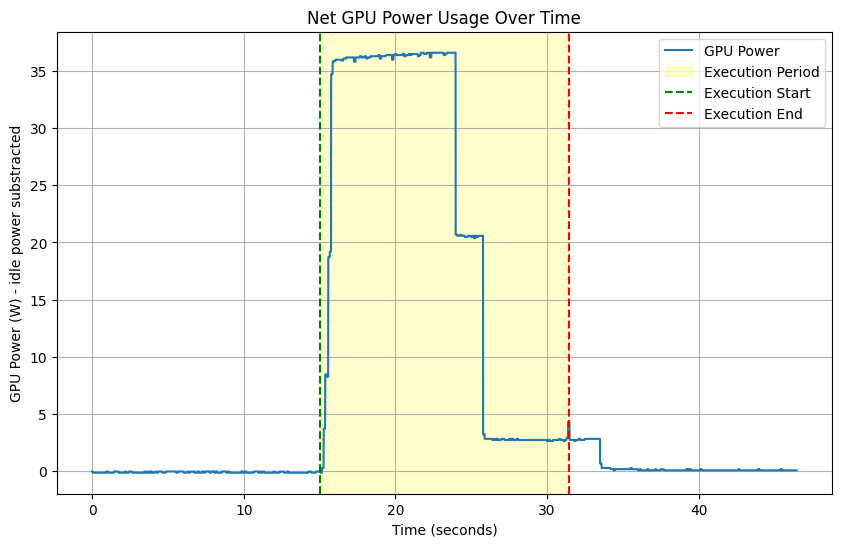

Start time: 15.0 -- End time: 31.452
Net (idle corrected) GPU energy consumption for generated_CUDA_gpu_net_power_results.csv:
  0.000099 kWh
  0.0991 Wh
  356.82 J
Average GPU power: 21.69 W +/- 15.56 
 with sample standard deviation.
Net Energy During Exe Runtime:   356.82 J
Code execution duration:  16.45 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

----- >>> System check AFTER exe code...

----- GPU Memory Status:
 GPU 0: 408 MiB used, 24167 MiB free, 24576 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 31.02 W, P0

--> SAVING code version: 6


----- POWER METRICS Feedback Loop  -----


*** DEBUG: code_version: 6 | tracking_best_version: 4 ***


--> ... prompt LLM to judge the validity of the refactored code.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code validation judge -----



Let's carefully compare the SOURCE CODE and the REFACTORED CODE for both functional equivalence and standard output similarity.

---

## 1. **Functional Equivalence**

### **Major Steps in Both Codes**

- **Table Size Calculation:**  
  Both codes compute the largest power-of-two table size that fits in 512MB, using half for safety.  
  - SOURCE: `Table size = 67108864`  
  - REFACTORED: `Table size = 2^26 = 67108864 words`  
  Both arrive at the same value.

- **Table Initialization:**  
  Both initialize the table so that `Table[i] = i` using a CUDA kernel.

- **Random Number Generation:**  
  Both use the same HPCC_starts algorithm to generate random seeds for the update kernel.  
  - SOURCE: Device function, seeds generated inside kernel.  
  - REFACTORED: Host function, seeds precomputed and copied to device constant memory.

- **Update Kernel:**  
  Both perform `NUPDATE = 8 * TableSize` atomic XORs on the table using random numbers.  
  - SOURCE: Each thread computes its own seed and updates.  
  - REFACTORED: Each thread reads its seed from constant memory and updates.

- **Validation:**  
  Both codes perform a host-side validation by reapplying the same random sequence and checking for errors.

- **Return Value:**  
  Both return 0 if errors ≤ 0.01 * TableSize, else 1.

### **Minor Differences**

- **Seed Calculation:**  
  The REFACTORED CODE precomputes seeds on the host and uses device constant memory, which is a performance and energy optimization, but does not change the algorithm's logic.

- **Atomic XOR and Masking:**  
  The REFACTORED CODE replaces a branch with a mask for the POLY application, which is functionally equivalent for LFSR.

- **Memory Allocation:**  
  The REFACTORED CODE uses `cudaHostAlloc` for pinned memory (for efficient transfer), while the SOURCE uses `posix_memalign`. Both allocate the same size and type.

- **Copy Back:**  
  The REFACTORED CODE uses asynchronous copy and a stream, which is an optimization, but does not affect correctness.

- **Error Reporting:**  
  The REFACTORED CODE prints `Errors = ... out of ... (PASS/FAIL)` instead of `Found ... errors in ... locations (PASS/FAIL)`. This is a formatting change.

---

## 2. **Standard Output Comparison**

### **SOURCE CODE Output**
```
Table size = 67108864
Main table size   = 2^26 = 67108864 words
Number of updates = 536870912
Average kernel execution time: 0.844261 (s)
Found 0 errors in 67108864 locations (PASS).
```

### **REFACTORED CODE Output**
```
Table size = 2^26 = 67108864 words
Average kernels time: 0.840327 s
Errors = 0 out of 67108864 (PASS)
```

#### **Analysis**
- **Table Size:**  
  Both display the table size, with the REFACTORED CODE combining the power-of-two and value in one line.  
  Acceptable formatting change.

- **Number of Updates:**  
  SOURCE prints `Number of updates = 536870912`.  
  REFACTORED does not print this line, but the logic is unchanged (`NUPDATE = 8 * TableSize = 536870912`).  
  Minor omission, but not a functional issue.

- **Timing:**  
  Both print average kernel execution time, with slightly different wording and formatting.  
  Numerical values are very close.

- **Validation:**  
  SOURCE: `Found 0 errors in 67108864 locations (PASS).`  
  REFACTORED: `Errors = 0 out of 67108864 (PASS)`  
  Wording is different, but the meaning and values are identical.

---

## 3. **Metrics Comparison**

- **Energy, Power, Duration:**  
  Both codes have nearly identical metrics, with the REFACTORED CODE slightly lower in energy and time, which is expected from optimizations.

---

## 4. **Conclusion**

### **Reasoning**
- The REFACTORED CODE performs all the same steps as the SOURCE CODE, with optimizations that do not affect correctness.
- The output is nearly equivalent in layout and content, with only minor formatting and omission of the "Number of updates" line, which is not critical for functional equivalence.
- The validation and timing outputs are consistent and correct.
- The metrics are similar, with slight improvements in energy and time.

### **Final Verdict**

**VALID**



----- END LLM RESPONSE -----



LLM JUDGE: START CODE ANALYSIS ---- 


--> ... prompt LLM to perform code analysis.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code analysis -----



<result>
fail
</result>

| Criterion Category                | Criteria                                                                                      | Pass/Fail |
|-----------------------------------|-----------------------------------------------------------------------------------------------|-----------|
| assumptions                       | TableSize is a power of two                                                                   | pass      |
| assumptions                       | NUPDATE (8 * TableSize) is divisible by K2_BLOCKSIZE (128)                                    | pass      |
| assumptions                       | GPU architecture supports 64-bit atomicXor operations                                         | pass      |
| assumptions                       | posix_memalign returns 1024‐byte‐aligned memory for host Table                                | fail      |
| assumptions                       | The command‐line argument <repeat> is a positive integer                                      | pass      |
| invariants                        | HPCC_starts(n) always returns the same 64‐bit LFSR state for a given input n                  | pass      |
| invariants                        | ran[j] remains a valid 64‐bit value throughout the update kernel                              | pass      |
| invariants                        | All Table indices are computed as (ran[j] & (TableSize-1)), ensuring in‐bounds access         | pass      |
| invariants                        | Total number of atomic XORs performed across all threads equals NUPDATE                       | pass      |
| invariants                        | Table entries are initialized to their index before any updates                               | pass      |
| design_patterns                   | Two‐phase kernel launch: first initTable to zero/initialize, then update to perform work      | pass      |
| design_patterns                   | Use of a Linear Feedback Shift Register (LFSR) for pseudo‐random number generation            | pass      |
| design_patterns                   | Atomic operations (atomicXor) to resolve concurrent updates to shared data structures         | pass      |
| design_patterns                   | Grid‐stride indexing in initTable for coalesced writes                                        | pass      |
| design_patterns                   | Host‐side replay validation of device computation                                             | pass      |
| memory_access_patterns            | initTable: contiguous, coalesced writes to d_Table by mapping threadIdx + blockIdx            | pass      |
| memory_access_patterns            | update: 128‐element ran[] written once per thread, then random atomicXor accesses into d_Table| pass      |
| memory_access_patterns            | Host validation: sequential reads and XOR updates to host‐side Table                          | pass      |
| memory_access_patterns            | Device memory reads/writes dominate kernels; no shared memory used                            | pass      |
| memory_allocation_deallocation    | Host: posix_memalign(&Table, 1024, TableSize * sizeof(u64Int); free(Table)                   | fail      |
| memory_allocation_deallocation    | Device: cudaMalloc(&d_Table, TableSize * sizeof(u64Int); cudaFree(d_Table)                    | pass      |
| memory_allocation_deallocation    | Device: cudaMalloc(&d_ran, 128 * sizeof(u64Int); cudaFree(d_ran)                              | fail      |
| other_key_characteristics         | TableSize and logTableSize derived from a fixed totalMem (512 MiB) at runtime                 | pass      |
| other_key_characteristics         | Block sizes defined by constants K1_BLOCKSIZE (256) and K2_BLOCKSIZE (128)                    | pass      |
| other_key_characteristics         | Use of __restrict__ on kernel pointer parameters to aid compiler optimizations                | pass      |
| other_key_characteristics         | Timing measured with std::chrono around repeated kernel launches                              | pass      |
| other_key_characteristics         | cudaDeviceSynchronize() ensures kernels finish before timing and data copy                    | pass      |

**Failing criteria:**
- Host: posix_memalign(&Table, 1024, TableSize * sizeof(u64Int); free(Table) (uses cudaHostAlloc instead)
- Device: cudaMalloc(&d_ran, 128 * sizeof(u64Int); cudaFree(d_ran) (no such allocation in code)

-- CHANGE JUDGE VALIDATION RESULT! --

Power and Energy Feedback data: 
----- Energy consumed (J) -----
  Source code: 358.75
  Refactored code: 356.82
----- Average power (W) -----
  Source code: 21.74
  Refactored code: 21.69
----- Runtime (s) -----
  Source code: 16.51
  Refactored code: 16.45
----- Tracking metrics -----
  Energy (J) history:  [358.75, 356.53, 361.05, 355.48, 354.54, 174.06, 356.82]
  Ave Power (W) history:  [21.74, 21.66, 21.95, 21.58, 21.54, 17.58, 21.69]
  Runtime (s) history:  [16.51, 16.46, 16.47, 16.47, 16.46, 9.9, 16.45]
  Valid code history:  ['SOURCE', 'basellm_stage1_VALID', 'VALID', 'VALID', 'VALID', 'INVALID', 'INVALID']
  Iteration log:  {'v1': {'self_correction_count': 1, 'energy_refactor_count': 0, 'LLM_temperature': 0.2}, 'v2': {'self_correction_count': 2, 'energy_refactor_count': 1, 'LLM_temperature': 0.2}, 'v3': {'self_correction_count': 0, 'energy_refactor_count': 2, 'LLM_temperature': 0.2}, 'v4': {'self_correction_count': 0, 'energy_refactor_cou



----- THE GENERATED CODE -----

(hidden)




----- POST-PROCESSING of GENERATED CODE -----


*** DEBUG: code_version: 6 | tracking_best_version: 4 ***
saving to file_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial2.cu
Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial2.cu', '-o', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial2']

Compilation of code successful!


Execute file: /home/cc/lassi/LASSI-EE/g

Waiting for the system to settle down for 5 seconds...: 100%|████████████████████████████████████████████| 5/5 [00:05<00:00,  1.00s/it]


executable_file:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial2
initial_dir:  /home/cc/lassi/LASSI-EE
directory_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16
executable:  randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial2
Working directory: /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16
Execute command: ['./randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial2', '10']

running: executable -  randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial2

----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION > -----

Table size = 2^26 = 6710

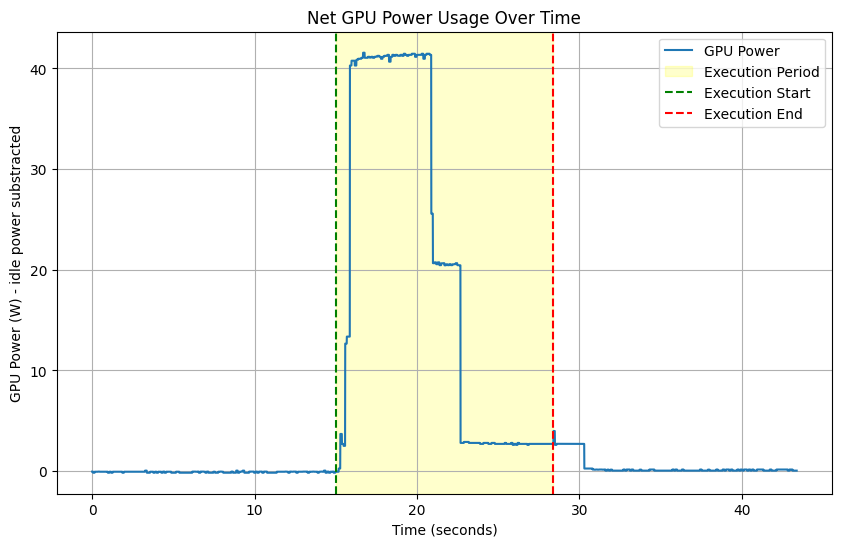

Start time: 15.0 -- End time: 28.384
Net (idle corrected) GPU energy consumption for generated_CUDA_gpu_net_power_results.csv:
  0.000073 kWh
  0.0734 Wh
  264.14 J
Average GPU power: 19.76 W +/- 17.63 
 with sample standard deviation.
Net Energy During Exe Runtime:   264.14 J
Code execution duration:  13.38 seconds
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!

----- >>> System check AFTER exe code...

----- GPU Memory Status:
 GPU 0: 408 MiB used, 24167 MiB free, 24576 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 31.02 W, P0

--> SAVING code version: 7


----- POWER METRICS Feedback Loop  -----


*** DEBUG: code_version: 7 | tracking_best_version: 4 ***


--> ... prompt LLM to judge the validity of the refactored code.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code validation judge -----



Let's carefully compare the SOURCE CODE and the REFACTORED CODE for both functional equivalence and standard output similarity.

---

## 1. **Functional Equivalence**

### **Core Algorithm**
- **Random Number Generation:**  
  Both codes use the same LFSR-based random number generator (HPCC_starts). The REFACTORED CODE moves seed generation for the update kernel to the host, precomputes 128 seeds, and stores them in device constant memory. The SOURCE CODE computes seeds on the device inside the kernel.  
  **Effect:** This is a valid optimization for energy efficiency and performance. The random sequence and update pattern are preserved.

- **Table Initialization:**  
  Both codes initialize the table on the device with table[i] = i.

- **Update Kernel:**  
  Both codes perform atomicXor updates to the table using the random sequence. The number of updates is identical: NUPDATE = 8 * TableSize.

- **Validation:**  
  Both codes perform a host-side validation by applying the same random sequence to the table and counting errors.

### **Other Changes**
- **Memory Allocation:**  
  The REFACTORED CODE uses cudaHostAlloc for pinned memory (energy/performance optimization), while the SOURCE CODE uses posix_memalign. Both allocate the same size.

- **Kernel Launch Parameters:**  
  Both codes use the same block and thread sizes.

- **Seed Generation:**  
  The REFACTORED CODE precomputes seeds on the host, which is functionally equivalent to the device-side computation in the SOURCE CODE.

- **Output and Error Checking:**  
  Both codes check for errors and return 0 for PASS, 1 for FAIL.

### **Conclusion:**  
**All core functionality is preserved.** The REFACTORED CODE is a more energy-efficient implementation of the same algorithm.

---

## 2. **Standard Output Comparison**

### **SOURCE CODE Output**
```
Table size = 67108864
Main table size   = 2^26 = 67108864 words
Number of updates = 536870912
Average kernel execution time: 0.844261 (s)
Found 0 errors in 67108864 locations (PASS).
```

### **REFACTORED CODE Output**
```
Table size = 2^26 = 67108864 words
Average kernels time: 0.534225 s
Errors = 0 out of 67108864 (PASS)
```

#### **Differences**
- **Table Size Display:**  
  - SOURCE CODE prints both "Table size = 67108864" and "Main table size   = 2^26 = 67108864 words".
  - REFACTORED CODE prints "Table size = 2^26 = 67108864 words".
  - **Conclusion:** The key information is present; the layout is slightly different but all details are included.

- **Number of Updates:**  
  - SOURCE CODE prints "Number of updates = 536870912".
  - REFACTORED CODE does not print this line.
  - **Conclusion:** This is a minor omission, but the update count is implicit in the code and validation. The omission does not affect functional equivalence.

- **Timing:**  
  - SOURCE CODE: "Average kernel execution time: 0.844261 (s)"
  - REFACTORED CODE: "Average kernels time: 0.534225 s"
  - **Conclusion:** The timing label is slightly different, but the meaning is clear. The REFACTORED CODE is faster, which is expected for an energy-efficient refactor.

- **Validation Output:**  
  - SOURCE CODE: "Found 0 errors in 67108864 locations (PASS)."
  - REFACTORED CODE: "Errors = 0 out of 67108864 (PASS)"
  - **Conclusion:** The wording is different, but the content is equivalent.

#### **Numerical Differences**
- **Timing:**  
  The REFACTORED CODE is faster, which is expected and reasonable.

- **Error Count:**  
  Both codes report zero errors, indicating correct functionality.

#### **Formatting Differences**
- The REFACTORED CODE omits the "Number of updates" line and slightly changes the wording of the validation output.  
- These are minor and do not affect the clarity or completeness of the output.

---

## 3. **Metrics Comparison**

- **Energy and Power:**  
  The REFACTORED CODE uses less energy and power, and runs faster. This is consistent with the goal of energy efficiency.

---

## 4. **Conclusion**

### **Reasoning**
- The REFACTORED CODE preserves all intended functionality of the SOURCE CODE.
- The printed output is nearly equivalent in content and layout, with only minor formatting and omission of the "Number of updates" line, which does not affect understanding or validation.
- The numerical results are consistent and correct.
- The energy and performance improvements are reasonable and expected.

---

**VALID**



----- END LLM RESPONSE -----



LLM JUDGE: START CODE ANALYSIS ---- 


--> ... prompt LLM to perform code analysis.


=====< LLM Prompt Not Shown >=====





----- LLM RESPONSE: code analysis -----



<result>
fail
</result>

| Criterion Category                | Criterion                                                                 | Pass/Fail |
|-----------------------------------|---------------------------------------------------------------------------|-----------|
| assumptions                      | TableSize is a power of two                                               | pass      |
| assumptions                      | NUPDATE divisible by K2_BLOCKSIZE                                         | pass      |
| assumptions                      | GPU supports 64-bit atomicXor                                             | pass      |
| assumptions                      | posix_memalign returns 1024-byte-aligned memory for host Table            | fail      |
| assumptions                      | <repeat> is a positive integer                                            | pass      |
| invariants                       | HPCC_starts(n) always returns same state for n                            | pass      |
| invariants                       | ran[j] remains valid 64-bit value                                         | pass      |
| invariants                       | Table indices computed as (ran[j] & (TableSize-1))                        | pass      |
| invariants                       | Total atomic XORs equals NUPDATE                                          | pass      |
| invariants                       | Table entries initialized to their index                                  | pass      |
| design_patterns                  | Two-phase kernel launch                                                   | pass      |
| design_patterns                  | LFSR for pseudo-random number generation                                  | pass      |
| design_patterns                  | Atomic operations to resolve concurrency                                  | pass      |
| design_patterns                  | Grid-stride indexing in initTable for coalesced writes                    | pass      |
| design_patterns                  | Host-side replay validation                                               | pass      |
| memory_access_patterns           | initTable: contiguous, coalesced writes                                   | pass      |
| memory_access_patterns           | update: 128-element ran[] written once/thread, random atomicXor           | pass      |
| memory_access_patterns           | Host validation: sequential reads/XOR updates                             | pass      |
| memory_access_patterns           | Device memory reads/writes dominate, no shared memory                     | pass      |
| memory_allocation_deallocation   | Host: posix_memalign(&Table, 1024, ...) + free(Table)                     | fail      |
| memory_allocation_deallocation   | Device: cudaMalloc/cudaFree d_Table                                       | pass      |
| memory_allocation_deallocation   | Device: cudaMalloc/cudaFree d_ran                                         | fail      |
| other_key_characteristics        | TableSize/logTableSize derived from fixed totalMem                        | pass      |
| other_key_characteristics        | Block sizes defined by constants                                          | pass      |
| other_key_characteristics        | __restrict__ on kernel pointer params                                     | pass      |
| other_key_characteristics        | Timing measured with std::chrono                                          | pass      |
| other_key_characteristics        | cudaDeviceSynchronize after kernels                                       | pass      |

**Criteria that fail:**
- Host: posix_memalign(&Table, 1024, ...) + free(Table) (uses cudaHostAlloc/cudaFreeHost instead)
- Device: cudaMalloc/cudaFree d_ran (no device allocation for d_ran; uses constant memory instead)

**All other criteria pass.**

-- CHANGE JUDGE VALIDATION RESULT! --

Power and Energy Feedback data: 
----- Energy consumed (J) -----
  Source code: 358.75
  Refactored code: 264.14
----- Average power (W) -----
  Source code: 21.74
  Refactored code: 19.76
----- Runtime (s) -----
  Source code: 16.51
  Refactored code: 13.38
----- Tracking metrics -----
  Energy (J) history:  [358.75, 356.53, 361.05, 355.48, 354.54, 174.06, 356.82, 264.14]
  Ave Power (W) history:  [21.74, 21.66, 21.95, 21.58, 21.54, 17.58, 21.69, 19.76]
  Runtime (s) history:  [16.51, 16.46, 16.47, 16.47, 16.46, 9.9, 16.45, 13.38]
  Valid code history:  ['SOURCE', 'basellm_stage1_VALID', 'VALID', 'VALID', 'VALID', 'INVALID', 'INVALID', 'INVALID']
  Iteration log:  {'v1': {'self_correction_count': 1, 'energy_refactor_count': 0, 'LLM_temperature': 0.2}, 'v2': {'self_correction_count': 2, 'energy_refactor_count': 1, 'LLM_temperature': 0.2}, 'v3': {'self_correction_count': 0, 'energy_refactor_count': 2, 'LLM_temperature': 0.2}, 'v4': {'self_correctio



----- THE GENERATED CODE -----

(hidden)




----- POST-PROCESSING of GENERATED CODE -----


*** DEBUG: code_version: 7 | tracking_best_version: 4 ***
saving to file_path:  /home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial2.cu
Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial2.cu', '-o', '/home/cc/lassi/LASSI-EE/generated_codes/experiment/exp0925_gpto4mini_randomAccess_ee__09-07-2025_t08_36_16/randomAccess-cuda_main_ee_refactorcode_CUDA_expexp0925_gpto4mini_randomAccess_ee_09-07-2025_t08_36_16_Trial2']

***** Compilation failed.

 Error message: 
/home/cc/lassi/LASSI-EE/gener

KeyboardInterrupt: 

In [6]:
# Experimental repeat for pass@k metrics
trial_number = 1
total_trials = 30

# Load prompt dictionary (to capture recent manual changes to script, if any)
prompts = PromptDictionary()

all_trials_start = time.time()

# Store the current home working directory (needed for code execution)
original_home_directory = os.getcwd()


# COLLECT THE EXPERIMENT CONFIGURATIONS
(
    app_folder_name, app_name, file_name, lines_of_code, source_lang, target_lang, model, model_coder, model_judge, num_ctx, num_ctx_coder,
    llm_source, use_context, use_context_summaries_only, few_shot_learning, run_code_analysis, context_knowledge_selection, source_folder, code_compiler,
    code_compiler_kwds, build_script, make_script, code_build_script, yes_execute, exe_input_parameters, experiment,
    display_response, test_with_error, generate_test_case, power_measure, test_code_first, yes_power_feedback, baseline_oneshot_goal,
    use_self_prompting, vary_llm_temp, verifyprompt, DATAFIELDNAMES
) = experimental_setup()

# IMPORT CONTEXT KNOWLEDGE FOR TARGET PROGRAMMING LANGUAGE
input_context = "[BACKGROUND KNOWLEDGE: CUDA C++ PROGRAMMING BEST PRACTICES] " + prompts.get_codeknowledge("cuda") + "\n\n"  # [/END GENERAL CUDA PROGRAMMING CONTEXT]
input_context = input_context + "[BACKGROUND KNOWLEDGE: CUDA C++ OPTIMIZATION GUIDE] " + prompts.get_codeknowledge(str(context_knowledge_selection)) + "\n\n"  #  [/END CUDA OPTIMIZATION CONTEXT]


# DEFINE PROMPT TEMPLATES
# TODO: MOST TASK PROMPT TEMPLATES WILL BE HANDLED BY THE PIPELINE METHODS
system_prompt_selection_index = source_lang + "_ee"  # "_to_" + target_lang  # Select which prompt to use from the prompt dictionary
this_llm_system_prompt = prompts.get_system_prompt(str(system_prompt_selection_index))

coderefactor_prompt_selection_index = source_lang  # + "_to_" + target_lang  # Select which prompt to use from the prompt dictionary
if (not baseline_oneshot_goal and use_self_prompting):
    this_llm_refactoredcode_prompt = prompts.get_code_ee_refactoring_prompt(str(coderefactor_prompt_selection_index))
else: 
    if use_context:
        this_llm_refactoredcode_prompt = prompts.get_code_ee_refactoring_prompt(str(coderefactor_prompt_selection_index + "_baseline"))
    else:
        this_llm_refactoredcode_prompt = prompts.get_code_ee_refactoring_prompt(str(coderefactor_prompt_selection_index + "_baseline_nocontext"))

# LOAD INPUT CODE TO REFACTOR
input_code_folder = source_folder + "/" + app_folder_name + "/"
if build_script:
    input_code_filename = app_name
elif make_script:
    input_code_filename = file_name
else:
    input_code_filename = app_folder_name + "-" + source_lang.lower() + "_main"
if source_lang == "OMP" or source_lang == "SYCL":
    input_code_extension = "cpp"
elif source_lang == "CUDA" or source_lang == "HIP":
    input_code_extension = "cu"
if make_script:
    source_file_directory = "generated_codes/" + input_code_folder
else:
    source_file_directory = "source_codes/" + input_code_folder
if make_script:
    # SELECT FILE TO REFACTOR from miniapp
    input_code_file_subdirectory = "device/cuda/"
    source_file_path = source_file_directory + input_code_file_subdirectory + input_code_filename + "." + input_code_extension
    source_file_path = os.path.abspath(source_file_path)
else:
    input_code_file_subdirectory = ""
    source_file_path = source_file_directory + input_code_filename + "." + input_code_extension
    source_file_path = os.path.abspath(source_file_path)
with open(source_file_path, 'r') as file:
    input_code = file.read()
file.close()


# SPECIFY OUTPUT CODE SAVE
if build_script:
    output_code_directory = "generated_codes/" + source_folder + "/" + app_folder_name
    output_code_file_name = app_name
elif make_script:
    output_code_file_name = file_name
    output_code_directory = "generated_codes/" + source_folder + "/" + app_folder_name
else:
    output_code_directory = "generated_codes/" + llm_source + "_" + model.replace('/', '--') + "/promptset_" + str(coderefactor_prompt_selection_index)
    output_code_file_name = input_code_filename + "_ee_refactorcode_" + source_lang + "_exp" + experiment

now = datetime.now(ZoneInfo("America/Chicago"))
dt_string = now.strftime("%m-%d-%Y_t%H_%M_%S")

# SPECIFIY DATA COLLECTION SAVE
experiment_data_directory = "generated_codes/experiment/" + experiment + "__" + dt_string
# Convert to absolute directory::
experiment_data_directory = os.path.abspath(experiment_data_directory)
experiment_data_file_object = init_data_collection(experiment_data_directory, DATAFIELDNAMES)
experiment_data = dict.fromkeys(DATAFIELDNAMES, None) # all keys start out as None

while trial_number <= total_trials:
    # CREATE METADATA RECORD CONTENT
    meta_data_file = "***** EXPERIMENT CONFIGURATION SUMMARY *****\n"
    meta_data_file += "\nDate-time: " + dt_string
    meta_data_file += "\nApplication: " + app_folder_name
    meta_data_file += "\n\nEE Refactoring: " + system_prompt_selection_index
    meta_data_file += "\n\nLLM Source: " + llm_source
    meta_data_file += "\nModel: " + model
    meta_data_file += "\nModel coder: " + model_coder
    meta_data_file += "\nModel judge: " + model_judge
    meta_data_file += "\nSystem Prompt Index: " + str(coderefactor_prompt_selection_index)
    meta_data_file += "\nCode file template: " + output_code_directory + "/" + output_code_file_name
    meta_data_file += "\n\nLLM System Prompt: " + "\n\n" + this_llm_system_prompt
    # meta_data_file += "\n\nLLM Prompt for Code Generation: " + "\n\n" + this_llm_refactoredcode_prompt
    meta_data_file += "\n\nPower measurement: " + str(power_measure)
    
    # Display metadata
    print("\n" + meta_data_file + "\n")
    
    print("\n\n" + color.BLUE + color.BOLD + "***** BEGIN THE LASSI ENERGY EFFICIENCY PIPELINE (v3) *****" + color.END + " Trial #: " + str(trial_number) + "\n\n")
    
    # RUN LASSI-EE PIPELINE
    complete = lassi.pipeline_v3.auto_code_llmgeneration_pipeline(
        prompts,
        this_llm_system_prompt,
        this_llm_refactoredcode_prompt,
        llm_source, 
        model,
        model_coder,
        model_judge,
        num_ctx,
        num_ctx_coder,
        # arrayormatrix_size_range,
        # thread_count_range,
        use_context,
        use_context_summaries_only,
        few_shot_learning,
        run_code_analysis,
        input_context,
        input_code_file_subdirectory,
        input_code,
        lines_of_code,
        # target_code,
        target_lang,
        input_code_extension,
        source_lang,
        code_compiler,
        code_compiler_kwds,
        build_script,
        make_script,
        code_build_script,
        output_code_directory,
        output_code_file_name,
        source_file_path,
        display_response,
        test_with_error,
        generate_test_case,
        yes_execute,
        exe_input_parameters,
        meta_data_file,
        power_measure,
        test_code_first,
        yes_power_feedback,
        dt_string,
        baseline_oneshot_goal,
        use_self_prompting,
        vary_llm_temp,
        experiment,
        verifyprompt,
        trial_number,
        experiment_data_directory,
        experiment_data_file_object,
        experiment_data
    )
    
    # Reset to original working directory
    os.chdir(original_home_directory)
    
    if complete:
        print("\n\n" + color.GREEN + color.BOLD + "***** LASSI PIPELINE COMPLETED *****\n\n" + color.END)
    else:
        print("\n\n" + color.RED + color.BOLD + "***** LASSI PIPELINE FAILED TO COMPLETE *****\n\n" + color.END)

    # Increment experiment counter
    trial_number = trial_number + 1


all_trials_end = time.time() - all_trials_start

print("\n\n" + color.PURPLE + color.BOLD + "***** ALL TRIALS COMPLETED ***** Total time (min): " + str(round(all_trials_end/60, 2)) + "\n\n" + color.END)